# Sampling-depth sensitivity: complete final QC versus nominal first 100 trajectories

Here we compare complete final-QC ensembles with a fixed nominal early cohort defined before QC: the first 20 ordered seeds × five AlphaFold model trajectories = 100 intended trajectories per protocol. Only trajectories surviving the same final-QC procedure are analyzed. This is a sampling-depth sensitivity analysis, not an independent replicate or a chronological record of model generation.

CaV1.2 and NaV1.5 use their final 3 Å allOK3 distance subsets. Kv2.1 uses the stricter allOK3 structural-interface/alignment-QC subset. The NaV1.5 comparison is QQQ vanilla versus corrected masked v1, matching the primary mutant analysis. CaV1.2 includes the WT masked candidate only; corrected masked mutant cohorts remain unavailable. Experimental markers retain the same PDB-specific colors and shapes used in the channel notebooks.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

repo_root = Path.cwd() if (Path.cwd() / 'shared').is_dir() else Path.cwd().parent
sys.path.insert(0, str(repo_root)) if str(repo_root) not in sys.path else None

from shared.data_access import resolve
from shared.dataset_selection import filtered_masked_distance_path, cav12_active_masked_distance_path, kv21_active_masked_distance_path, nav15_active_masked_distance_path

from shared.plotting import CAV12_PALETTE, KV21_PALETTE, NAV15_PALETTE, ACCENT_PALETTE
from shared.sampling_depth_analysis import (
    SUBSETS, load_final_qc_pair, plot_sampling_depth_condition,
    summarize_sampling_depth,
)
from shared.presentation_export import install_notebook_figure_export

install_notebook_figure_export(
    repo_root / 'docs' / 'figures' / 'notebook_exports' / 'cross_project',
    'SamplingDepth_AllOK3_vs_First100',
)
sns.set_theme(style='whitegrid', context='notebook')


## Final-QC dataset catalog


In [2]:
DATASETS = {
    'CaV1.2 WT': {
        'channel': 'Cav1.2', 'condition': 'WT',
        'colors': {'vanilla': CAV12_PALETTE['WT_VAN'], 'masked': CAV12_PALETTE['WT_HM']},
        'vanilla': resolve('cav12/dataDistances/26-02-10_Cav12_wt_vanillaAF2_distances_all_ok_rmsd_3A.csv'),
        'masked': resolve(filtered_masked_distance_path(repo_root, 'cav12', 'WT')),
    },
    'Kv2.1 WT': {
        'channel': 'Kv2.1', 'condition': 'WT',
        'colors': {'vanilla': KV21_PALETTE['WT_VAN'], 'masked': KV21_PALETTE['WT_HM']},
        'vanilla': resolve('kv21/dataDistances/26-02-11_Kv2.1_wt_vanillaAF2_distances_all_ok_rmsd_3A_structural_interface_qc.csv'),
        'masked': resolve(filtered_masked_distance_path(repo_root, 'kv21', 'WT')),
    },
    'Kv2.1 L403A': {
        'channel': 'Kv2.1', 'condition': 'L403A',
        'colors': {'vanilla': KV21_PALETTE['L403A_VAN'], 'masked': KV21_PALETTE['L403A_HM']},
        'vanilla': resolve('kv21/dataDistances/26-02-11_Kv2.1_l403a_vanillaAF2_distances_all_ok_rmsd_3A_structural_interface_qc.csv'),
        'masked': resolve(filtered_masked_distance_path(repo_root, 'kv21', 'L403A')),
    },
    'Kv2.1 F412L': {
        'channel': 'Kv2.1', 'condition': 'F412L',
        'colors': {'vanilla': KV21_PALETTE['F412L_VAN'], 'masked': KV21_PALETTE['F412L_HM']},
        'vanilla': resolve('kv21/dataDistances/26-02-11_Kv2.1_f412l_vanillaAF2_distances_all_ok_rmsd_3A_structural_interface_qc.csv'),
        'masked': resolve(filtered_masked_distance_path(repo_root, 'kv21', 'F412L')),
    },
    'NaV1.5 QQQ': {
        'channel': 'Nav1.5', 'condition': 'QQQ | corrected masked v1',
        'colors': {'vanilla': NAV15_PALETTE['QQQ_VAN'], 'masked': NAV15_PALETTE['QQQ_HM']},
        'vanilla': resolve('nav15/dataDistances/26-07-27_Nav15_qqq_vanilla_AF2_distances_all_ok_rmsd_3A.csv'),
        'masked': resolve(filtered_masked_distance_path(repo_root, 'nav15', 'QQQ', 'v1')),
    },
}

path_audit = pd.DataFrame([
    {'Dataset': name, 'Protocol': protocol, 'Path': str(config[protocol]), 'Exists': config[protocol].is_file()}
    for name, config in DATASETS.items() for protocol in ('vanilla', 'masked')
])
display(path_audit)
assert path_audit['Exists'].all(), 'A required final-QC distance table is missing.'


,Dataset,Protocol,Path,Exists
0,CaV1.2 WT,vanilla,/Users/ahernandezgonzalez/LabNotebook/26-10/vg...,True
1,CaV1.2 WT,masked,/Users/ahernandezgonzalez/LabNotebook/26-10/vg...,True
2,Kv2.1 WT,vanilla,/Users/ahernandezgonzalez/LabNotebook/26-10/vg...,True
3,Kv2.1 WT,masked,/Users/ahernandezgonzalez/LabNotebook/26-10/vg...,True
4,Kv2.1 L403A,vanilla,/Users/ahernandezgonzalez/LabNotebook/26-10/vg...,True
5,Kv2.1 L403A,masked,/Users/ahernandezgonzalez/LabNotebook/26-10/vg...,True
6,Kv2.1 F412L,vanilla,/Users/ahernandezgonzalez/LabNotebook/26-10/vg...,True
7,Kv2.1 F412L,masked,/Users/ahernandezgonzalez/LabNotebook/26-10/vg...,True
8,NaV1.5 QQQ,vanilla,/Users/ahernandezgonzalez/LabNotebook/26-10/vg...,True
9,NaV1.5 QQQ,masked,/Users/ahernandezgonzalez/LabNotebook/26-10/vg...,True


## Structural coordinates

The comparison uses the same selectivity-filter, voltage-sensor, and intracellular-gate coordinates as the channel notebooks. Experimental overlays are included only where the selected aliases have validated residue correspondences. The Kv2.1 WT panels additionally use 9O10–9O13 as an experimental state ladder: VSD-up/high-K, VSD-up/low-K, two-VSD-down/open-pore, and four-VSD-down/constricted-pore. These state markers are omitted from the mutant panels because they are not mutation-matched references.


In [3]:
REGIONS = {
    'Cav1.2': {
        'selectivity_filter': {'E363-E706':'CA_GLU363_CA-GLU706_CA', 'E363-E1135':'CA_GLU363_CA-GLU1135_CA', 'E363-E1464':'CA_GLU363_CA-GLU1464_CA', 'E706-E1135':'CA_GLU706_CA-GLU1135_CA', 'E706-E1464':'CA_GLU706_CA-GLU1464_CA', 'E1135-E1464':'CA_GLU1135_CA-GLU1464_CA'},
        'vsds': {'F170-R237':'CA_ARG237_CA-PHE170_CA', 'F170-R246':'CA_ARG246_CA-PHE170_CA', 'F567-R620':'CA_ARG620_CA-PHE567_CA', 'F567-K629':'CA_LYS629_CA-PHE567_CA', 'F940-K1015':'CA_LYS1015_CA-PHE940_CA', 'F940-K1031':'CA_ARG1031_CA-PHE940_CA', 'F1278-R1377':'CA_ARG1377_CA-PHE1278_CA', 'F1278-K1386':'CA_LYS1386_CA-PHE1278_CA'},
        'intracellular_gate': {'L401-L749':'CA_LEU401_CA-LEU749_CA', 'L401-V1182':'CA_LEU401_CA-VAL1182_CA', 'L401-I1516':'CA_LEU401_CA-ILE1516_CA', 'L749-V1182':'CA_LEU749_CA-VAL1182_CA', 'L749-I1516':'CA_LEU749_CA-ILE1516_CA', 'V1182-I1516':'CA_VAL1182_CA-ILE1516_CA'},
    },
    'Kv2.1': {
        'selectivity_filter': {'G375 A-B':'CA_CA_A_GLY377_CA-B_GLY377_CA', 'G375 A-C':'CA_CA_A_GLY377_CA-C_GLY377_CA', 'G375 A-D':'CA_CA_A_GLY377_CA-D_GLY377_CA', 'G375 B-C':'CA_CA_B_GLY377_CA-C_GLY377_CA', 'G375 B-D':'CA_CA_B_GLY377_CA-D_GLY377_CA', 'G375 C-D':'CA_CA_C_GLY377_CA-D_GLY377_CA'},
        'vsds': {'F236-R289 A':'CA_CA_A_ARG291_CA-A_PHE238_CA', 'F236-R308 A':'CA_CA_A_ARG310_CA-A_PHE238_CA'},
        'intracellular_gate': {'A402 A-B':'CA_CA_A_ALA404_CA-B_ALA404_CA', 'A402 A-C':'CA_CA_A_ALA404_CA-C_ALA404_CA', 'A402 A-D':'CA_CA_A_ALA404_CA-D_ALA404_CA', 'A402 B-C':'CA_CA_B_ALA404_CA-C_ALA404_CA', 'A402 B-D':'CA_CA_B_ALA404_CA-D_ALA404_CA', 'A402 C-D':'CA_CA_C_ALA404_CA-D_ALA404_CA'},
    },
    'Nav1.5': {
        'selectivity_filter': {'D373-E704':'CA_ASP373_CA-GLU704_CA', 'D373-K1103':'CA_ASP373_CA-LYS1103_CA', 'D373-A1395':'CA_ASP373_CA-ALA1395_CA', 'E704-K1103':'CA_GLU704_CA-LYS1103_CA', 'E704-A1395':'CA_GLU704_CA-ALA1395_CA', 'K1103-A1395':'CA_LYS1103_CA-ALA1395_CA'},
        'vsds': {'F165-R220':'CA_ARG220_CA-PHE165_CA', 'F165-R229':'CA_LYS229_CA-PHE165_CA', 'F560-R612':'CA_ARG612_CA-PHE560_CA', 'F560-K624':'CA_LYS624_CA-PHE560_CA', 'F934-R984':'CA_LYS984_CA-PHE934_CA', 'F934-K1000':'CA_ARG1000_CA-PHE934_CA', 'F1251-R1307':'CA_ARG1307_CA-PHE1251_CA', 'F1251-R1322':'CA_ARG1322_CA-PHE1251_CA'},
        'intracellular_gate': {'M415-A742':'CA_MET415_CA-ALA742_CA', 'M415-I1154':'CA_MET415_CA-ILE1154_CA', 'M415-I1455':'CA_MET415_CA-ILE1455_CA', 'A742-I1154':'CA_ALA742_CA-ILE1154_CA', 'A742-I1455':'CA_ALA742_CA-ILE1455_CA', 'I1154-I1455':'CA_ILE1154_CA-ILE1455_CA'},
    },
}


## Complete versus reduced sampling

Each trajectory contributes one structure: its latest recycle surviving final QC. Each upper panel uses these representatives from the complete final-QC cohort. Each lower panel uses representatives surviving from the nominal first 100 trajectories: five model trajectories from each of the first 20 ordered seeds. This keeps the intended seed/model cohort fixed before QC rather than extending farther into the run until 100 survivors are accumulated. A difference between panels indicates sensitivity to sampling depth; it does not establish a separate conformational population.

In [4]:
summary_rows = []
ranking_tables = {}
figure_dir = repo_root / 'docs' / 'figures' / 'sampling_depth'
table_dir = repo_root / 'docs' / 'tables' / 'sampling_depth'
figure_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

for name, config in DATASETS.items():
    print(f'Loading {name}')
    frames = load_final_qc_pair({'vanilla': config['vanilla'], 'masked': config['masked']})
    for region, aliases in REGIONS[config['channel']].items():
        ranking, figure = plot_sampling_depth_condition(
            repo_root, config['condition'], config['channel'], region,
            frames, aliases, config['colors'], top_n=8,
        )
        if figure is None:
            print(f'No complete shared columns: {name} | {region}')
            continue
        display(figure)
        safe_name = name.lower().replace(' ', '_').replace('.', '')
        safe_region = region.replace(' ', '_')
        figure.savefig(figure_dir / f'{safe_name}_{safe_region}.png', dpi=400, bbox_inches='tight')
        ranking.to_csv(table_dir / f'{safe_name}_{safe_region}_ranking.csv', index=False)
        ranking_tables[(name, region)] = ranking
        summary_rows.extend(summarize_sampling_depth(name, region, frames, ranking))
        plt.close(figure)

sampling_summary = pd.DataFrame(summary_rows)
sampling_summary.to_csv(table_dir / 'sampling_depth_summary.csv', index=False)
display(sampling_summary.round(3))


Loading CaV1.2 WT


<Figure size 1280x1050 with 2 Axes>

<Figure size 1280x1050 with 2 Axes>

<Figure size 1280x1050 with 2 Axes>

Loading Kv2.1 WT


<Figure size 1280x1050 with 2 Axes>

... (11 outputs left out)

<Figure size 1280x1050 with 2 Axes>

<Figure size 1280x1050 with 2 Axes>

<Figure size 1280x1050 with 2 Axes>

,Condition,Region,Subset,Shared distances,Median masked/vanilla IQR ratio,Fraction broader under masking,Vanilla rows,Masked rows
0,CaV1.2 WT,selectivity_filter,Complete final QC,6,0.985,0.500,500,500
1,CaV1.2 WT,selectivity_filter,QC survivors from nominal first 100,6,1.000,0.500,100,100
2,CaV1.2 WT,vsds,Complete final QC,8,1.300,0.625,500,500
3,CaV1.2 WT,vsds,QC survivors from nominal first 100,8,1.286,0.625,100,100
4,CaV1.2 WT,intracellular_gate,Complete final QC,6,1.338,0.667,500,500
5,CaV1.2 WT,intracellular_gate,QC survivors from nominal first 100,6,1.439,0.667,100,100
6,Kv2.1 WT,selectivity_filter,Complete final QC,6,0.194,0.000,490,463
7,Kv2.1 WT,selectivity_filter,QC survivors from nominal first 100,6,0.197,0.000,98,95
8,Kv2.1 WT,vsds,Complete final QC,2,0.854,0.000,490,463
9,Kv2.1 WT,vsds,QC survivors from nominal first 100,2,0.819,0.000,98,95


## Cross-condition sensitivity summary

Values close between the two bars indicate that the qualitative masking effect is already visible with QC survivors from nominal first 100. Large disagreements identify conclusions that depend on deeper sampling and should not be inferred from a small ensemble.


In [5]:
plot_data = sampling_summary.copy()
plot_data['Condition and region'] = plot_data['Condition'] + ' | ' + plot_data['Region']
subset_palette = {'Complete final QC': ACCENT_PALETTE['PINK'], 'QC survivors from nominal first 100': ACCENT_PALETTE['CORAL']}
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)
sns.barplot(data=plot_data, x='Condition and region', y='Median masked/vanilla IQR ratio', hue='Subset', palette=subset_palette, ax=axes[0])
axes[0].axhline(1, color='#555555', linewidth=0.8, linestyle='--')
axes[0].set_title('Magnitude of the masking-associated variability difference')
sns.barplot(data=plot_data, x='Condition and region', y='Fraction broader under masking', hue='Subset', palette=subset_palette, ax=axes[1])
axes[1].axhline(0.5, color='#555555', linewidth=0.8, linestyle='--')
axes[1].set_title('Fraction of coordinates broader in masked ensembles')
axes[1].tick_params(axis='x', rotation=55)
for axis in axes:
    axis.grid(axis='x', visible=False)
    sns.despine(ax=axis)
fig.suptitle('Sampling-depth sensitivity across final-QC ensembles', fontsize=17, fontweight='semibold')
fig.tight_layout()
display(fig)
fig.savefig(figure_dir / 'sampling_depth_cross_condition_summary.png', dpi=400, bbox_inches='tight')


<Figure size 1400x1000 with 2 Axes>

## Cross-project retention by recycle

These heatmaps use the same final-QC CSVs analyzed above. Each cell corresponds to one recycle and is annotated with the number of nominal seed/model trajectories represented after final QC. The upper row uses the fixed first 20 seeds (100 nominal trajectories); the lower row uses all 100 seeds (500 nominal trajectories). Missing trajectories are not replaced. Color gradients follow the project palettes: blue for CaV1.2, green for Kv2.1, and purple for NaV1.5.

In [6]:
from shared.recycle_retention_analysis import run_recycle_retention_analysis
recycle_retention_table, recycle_retention_figures = run_recycle_retention_analysis(
    DATASETS,
    repo_root/'docs'/'figures'/'sampling_depth',
    repo_root/'docs'/'tables'/'sampling_depth',
)
display(recycle_retention_table)
display(recycle_retention_figures['retained_fraction'])
display(recycle_retention_figures['excluded'])
plt.close('all')

,channel,dataset,condition,protocol,cohort,recycle,nominal_trajectories,retained,excluded,retained_fraction
0,Cav1.2,CaV1.2 WT,WT,vanilla,Nominal first 100,1,100,100,0,1.0
1,Cav1.2,CaV1.2 WT,WT,vanilla,Nominal first 100,2,100,100,0,1.0
2,Cav1.2,CaV1.2 WT,WT,vanilla,Nominal first 100,3,100,100,0,1.0
3,Cav1.2,CaV1.2 WT,WT,vanilla,Nominal first 100,4,100,100,0,1.0
4,Cav1.2,CaV1.2 WT,WT,vanilla,Nominal first 100,5,100,100,0,1.0
...,...,...,...,...,...,...,...,...,...,...
195,Nav1.5,NaV1.5 QQQ,QQQ | corrected masked v1,masked,Full 500,6,500,500,0,1.0
196,Nav1.5,NaV1.5 QQQ,QQQ | corrected masked v1,masked,Full 500,7,500,500,0,1.0
197,Nav1.5,NaV1.5 QQQ,QQQ | corrected masked v1,masked,Full 500,8,500,500,0,1.0
198,Nav1.5,NaV1.5 QQQ,QQQ | corrected masked v1,masked,Full 500,9,500,500,0,1.0


<Figure size 1700x1000 with 8 Axes>

<Figure size 1700x1000 with 8 Axes>

## Cross-project retention by recycle

These heatmaps use the same final-QC CSVs analyzed above. Each cell corresponds to one recycle and is annotated with the number of nominal seed/model trajectories represented after final QC. The upper row uses the fixed first 20 seeds (100 nominal trajectories); the lower row uses all 100 seeds (500 nominal trajectories). Missing trajectories are not replaced. Color gradients follow the project palettes: blue for CaV1.2, green for Kv2.1, and purple for NaV1.5.

In [7]:
from shared.recycle_retention_analysis import run_recycle_retention_analysis
recycle_retention_table, recycle_retention_figures = run_recycle_retention_analysis(
    DATASETS,
    repo_root/'docs'/'figures'/'sampling_depth',
    repo_root/'docs'/'tables'/'sampling_depth',
)
display(recycle_retention_table)
display(recycle_retention_figures['retained_fraction'])
display(recycle_retention_figures['excluded'])
plt.close('all')

,channel,dataset,condition,protocol,cohort,recycle,nominal_trajectories,retained,excluded,retained_fraction
0,Cav1.2,CaV1.2 WT,WT,vanilla,Nominal first 100,1,100,100,0,1.0
1,Cav1.2,CaV1.2 WT,WT,vanilla,Nominal first 100,2,100,100,0,1.0
2,Cav1.2,CaV1.2 WT,WT,vanilla,Nominal first 100,3,100,100,0,1.0
3,Cav1.2,CaV1.2 WT,WT,vanilla,Nominal first 100,4,100,100,0,1.0
4,Cav1.2,CaV1.2 WT,WT,vanilla,Nominal first 100,5,100,100,0,1.0
...,...,...,...,...,...,...,...,...,...,...
195,Nav1.5,NaV1.5 QQQ,QQQ | corrected masked v1,masked,Full 500,6,500,500,0,1.0
196,Nav1.5,NaV1.5 QQQ,QQQ | corrected masked v1,masked,Full 500,7,500,500,0,1.0
197,Nav1.5,NaV1.5 QQQ,QQQ | corrected masked v1,masked,Full 500,8,500,500,0,1.0
198,Nav1.5,NaV1.5 QQQ,QQQ | corrected masked v1,masked,Full 500,9,500,500,0,1.0


<Figure size 1700x1000 with 8 Axes>

<Figure size 1700x1000 with 8 Axes>

## Cross-project retention by recycle

These heatmaps use the same final-QC CSVs analyzed above. Each cell corresponds to one recycle and is annotated with the number of nominal seed/model trajectories represented after final QC. The upper row uses the fixed first 20 seeds (100 nominal trajectories); the lower row uses all 100 seeds (500 nominal trajectories). Missing trajectories are not replaced. Color gradients follow the project palettes: blue for CaV1.2, green for Kv2.1, and purple for NaV1.5.

In [8]:
from shared.recycle_retention_analysis import run_recycle_retention_analysis
recycle_retention_table, recycle_retention_figures = run_recycle_retention_analysis(
    DATASETS,
    repo_root/'docs'/'figures'/'sampling_depth',
    repo_root/'docs'/'tables'/'sampling_depth',
)
display(recycle_retention_table)
display(recycle_retention_figures['retained_fraction'])
display(recycle_retention_figures['excluded'])
plt.close('all')

,channel,dataset,condition,protocol,cohort,recycle,nominal_trajectories,retained,excluded,retained_fraction
0,Cav1.2,CaV1.2 WT,WT,vanilla,Nominal first 100,1,100,100,0,1.0
1,Cav1.2,CaV1.2 WT,WT,vanilla,Nominal first 100,2,100,100,0,1.0
2,Cav1.2,CaV1.2 WT,WT,vanilla,Nominal first 100,3,100,100,0,1.0
3,Cav1.2,CaV1.2 WT,WT,vanilla,Nominal first 100,4,100,100,0,1.0
4,Cav1.2,CaV1.2 WT,WT,vanilla,Nominal first 100,5,100,100,0,1.0
...,...,...,...,...,...,...,...,...,...,...
195,Nav1.5,NaV1.5 QQQ,QQQ | corrected masked v1,masked,Full 500,6,500,500,0,1.0
196,Nav1.5,NaV1.5 QQQ,QQQ | corrected masked v1,masked,Full 500,7,500,500,0,1.0
197,Nav1.5,NaV1.5 QQQ,QQQ | corrected masked v1,masked,Full 500,8,500,500,0,1.0
198,Nav1.5,NaV1.5 QQQ,QQQ | corrected masked v1,masked,Full 500,9,500,500,0,1.0


<Figure size 1700x1000 with 8 Axes>

<Figure size 1700x1000 with 8 Axes>

## L403A all-distance equal-seed-depth extension

The panels above test selected structural coordinates using the same fixed nominal early cohort: the first 20 ordered seeds × five model trajectories = 100 intended trajectories per protocol, followed by the final-QC cross-check. The raw Kv2.1 tables share 1,410 distance columns, but 864 are raw interchain A–B/A–C/etc. measurements that are not invariant to homotetramer chain relabeling. Those columns are excluded from broadening inference. This extension analyzes the 546 chain-label-safe intrachain distances (273 Cα and 273 shortest-heavy-atom distances).

At each depth, the nominal seed/model cohort is fixed before QC and missing trajectories are not replaced. One structure represents each surviving trajectory: the latest recycle that passes final QC. The nominal generated-trajectory budgets are 20, 40, 60, 80, and 100 (4, 8, 12, 16, and 20 seeds), followed by the complete 100-seed cohort. This is deterministic rather than timestamped chronological generation. Global IQR is descriptive. Primary per-distance inference uses one within-seed IQR and compares vanilla versus masked seed distributions with two-sided Mann–Whitney tests followed by Benjamini–Hochberg FDR correction within each depth. Brown–Forsythe tests provide a trajectory-level sensitivity analysis. Wasserstein separation uses the single representatives.

In [9]:
from IPython.display import Image, display
from kv21.run_l403a_all_distance_sampling_analysis import run as run_all_distance_sampling, TAB as ALL_DISTANCE_TAB, FIG as ALL_DISTANCE_FIG
all_distance_result = run_all_distance_sampling()
paper_statistics = pd.read_csv(ALL_DISTANCE_TAB/'l403a_all_distance_paper_statistics_summary.csv')
stability_statistics = pd.read_csv(ALL_DISTANCE_TAB/'l403a_all_distance_sampling_stability.csv')
trajectory_retention_summary = pd.read_csv(ALL_DISTANCE_TAB/'l403a_first100_nominal_trajectory_qc_summary.csv')
trajectory_retention_audit = pd.read_csv(ALL_DISTANCE_TAB/'l403a_first100_nominal_trajectory_qc_audit.csv')
retention_test = pd.read_csv(ALL_DISTANCE_TAB/'l403a_first100_qc_retention_fisher_test.csv')
overall_seed_breadth_summary = pd.read_csv(ALL_DISTANCE_TAB/'l403a_first100_seed_level_global_breadth_summary.csv')
equal_count_rarefaction_summary = pd.read_csv(ALL_DISTANCE_TAB/'l403a_first100_equal_count_rarefaction_summary.csv')
random_seed_saturation_summary = pd.read_csv(ALL_DISTANCE_TAB/'l403a_random_seed_saturation_summary.csv')
first100_distribution_statistics_summary = pd.read_csv(ALL_DISTANCE_TAB/'l403a_first100_seed_block_distribution_statistics_summary.csv')
full_distribution_statistics_summary = pd.read_csv(ALL_DISTANCE_TAB/'l403a_full_seed_block_distribution_statistics_summary.csv')
first100_vs_full_directional_statistics = pd.read_csv(ALL_DISTANCE_TAB/'l403a_first100_vs_full_directional_breadth_statistics.csv')
display(paper_statistics)
display(stability_statistics)

Merged companion distance table: kv21/dataDistances/26-11-12_Kv2.1_l403a_masked_v3_50pct_AF2_distances_extra_all_ok_rmsd_3A.csv
Kv2.1 L403A masked: requested=all_ok_3; actual=all_ok_3; path=kv21/dataDistances/26-11-12_Kv2.1_l403a_masked_v3_50pct_AF2_distances_all_ok_rmsd_3A.csv


/Users/ahernandezgonzalez/miniforge3/lib/python3.13/site-packages/scipy/stats/_morestats.py:3525: RuntimeWarning: invalid value encountered in divide
  W = numer / denom
/Users/ahernandezgonzalez/miniforge3/lib/python3.13/site-packages/scipy/stats/_morestats.py:3525: RuntimeWarning: invalid value encountered in divide
  W = numer / denom


/Users/ahernandezgonzalez/miniforge3/lib/python3.13/site-packages/scipy/stats/_morestats.py:3525: RuntimeWarning: invalid value encountered in divide
  W = numer / denom


/Users/ahernandezgonzalez/miniforge3/lib/python3.13/site-packages/scipy/stats/_morestats.py:3525: RuntimeWarning: invalid value encountered in divide
  W = numer / denom
/Users/ahernandezgonzalez/miniforge3/lib/python3.13/site-packages/scipy/stats/_morestats.py:3525: RuntimeWarning: invalid value encountered in divide
  W = numer / denom


/Users/ahernandezgonzalez/miniforge3/lib/python3.13/site-packages/scipy/stats/_morestats.py:3525: RuntimeWarning: invalid value encountered in divide
  W = numer / denom


/Users/ahernandezgonzalez/Repositories/vgci_mutants/kv21/run_l403a_all_distance_sampling_analysis.py:408: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=z,x='protocol',y='Distance_A',order=['vanilla','masked'],
/Users/ahernandezgonzalez/Repositories/vgci_mutants/kv21/run_l403a_all_distance_sampling_analysis.py:412: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Vanilla','Targeted masking'])
/Users/ahernandezgonzalez/Repositories/vgci_mutants/kv21/run_l403a_all_distance_sampling_analysis.py:408: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=z,x='protocol',y='Distance_A',ord

/Users/ahernandezgonzalez/Repositories/vgci_mutants/kv21/run_l403a_all_distance_sampling_analysis.py:458: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0].set_xticklabels(['Vanilla','Targeted masking'])


/Users/ahernandezgonzalez/Repositories/vgci_mutants/kv21/run_l403a_all_distance_sampling_analysis.py:520: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0,0].set_xticklabels(['Vanilla','Targeted masking'])


,depth,distances,median_global_IQR_ratio,fraction_global_broader_masked,median_seed_IQR_ratio,fraction_seed_broader_masked,fraction_seed_breadth_q_lt_0.05,fraction_significant_broader_masked,fraction_significant_narrower_masked,median_trajectory_W1_A,median_normalized_W1,vanilla_rows,masked_rows,vanilla_seeds,masked_seeds,n_global_broader_masked,n_significant_broader_masked,n_significant_narrower_masked
0,4,546,0.763030,0.375458,0.727273,0.369963,0.000000,0.000000,0.000000,0.505961,0.972479,19,20,4,4,205,0,0
1,8,546,0.785714,0.353480,0.768318,0.333333,0.485348,0.152015,0.331502,0.434452,0.959922,39,40,8,8,193,83,181
2,12,546,0.750000,0.327839,0.750000,0.342491,0.611722,0.177656,0.434066,0.423263,0.937188,59,60,12,12,179,97,237
3,16,546,0.771264,0.349817,0.785714,0.357143,0.664835,0.212454,0.450549,0.436103,0.947920,79,80,16,16,191,116,246
4,20,546,0.750000,0.320513,0.760714,0.349817,0.675824,0.201465,0.470696,0.503181,0.948164,99,100,20,20,175,110,257
5,Full QC,546,0.700000,0.309524,0.767680,0.329670,0.833333,0.261905,0.558608,0.418415,0.911698,484,497,100,100,169,143,305


,depth,metric,spearman_vs_full,p,same_direction_fraction
0,4,global_log2_IQR_ratio,0.869910,4.018237e-169,0.816850
1,4,seed_log2_IQR_ratio,0.886648,2.388880e-184,0.816850
2,4,trajectory_median_W1_A,0.981467,0.000000e+00,NaN
3,8,global_log2_IQR_ratio,0.924948,1.066083e-230,0.858974
4,8,seed_log2_IQR_ratio,0.922967,9.662226e-228,0.877289
5,8,trajectory_median_W1_A,0.994580,0.000000e+00,NaN
6,12,global_log2_IQR_ratio,0.944228,1.331095e-264,0.882784
7,12,seed_log2_IQR_ratio,0.947551,1.168668e-271,0.899267
8,12,trajectory_median_W1_A,0.997926,0.000000e+00,NaN
9,16,global_log2_IQR_ratio,0.947280,4.558385e-271,0.897436


### Final-QC cross-check for the nominal first 100 trajectories

,protocol,nominal_trajectories,retained_trajectories,first_seed,last_seed,retained_model_recycle_rows,excluded_trajectories,trajectory_retention_fraction
0,vanilla,100,99,55,74,910,1,0.99
1,masked,100,100,33,52,933,0,1.00


,test,masked_retained,masked_excluded,vanilla_retained,vanilla_excluded,odds_ratio_masked_vs_vanilla,p
0,two-sided Fisher exact,100,0,99,1,inf,1.0


,protocol,nominal_trajectory_order,seed_rank,seed,model_number,final_qc_retained,final_qc_rows,retained_recycles
18,vanilla,19,4,58,4,False,0,NaN


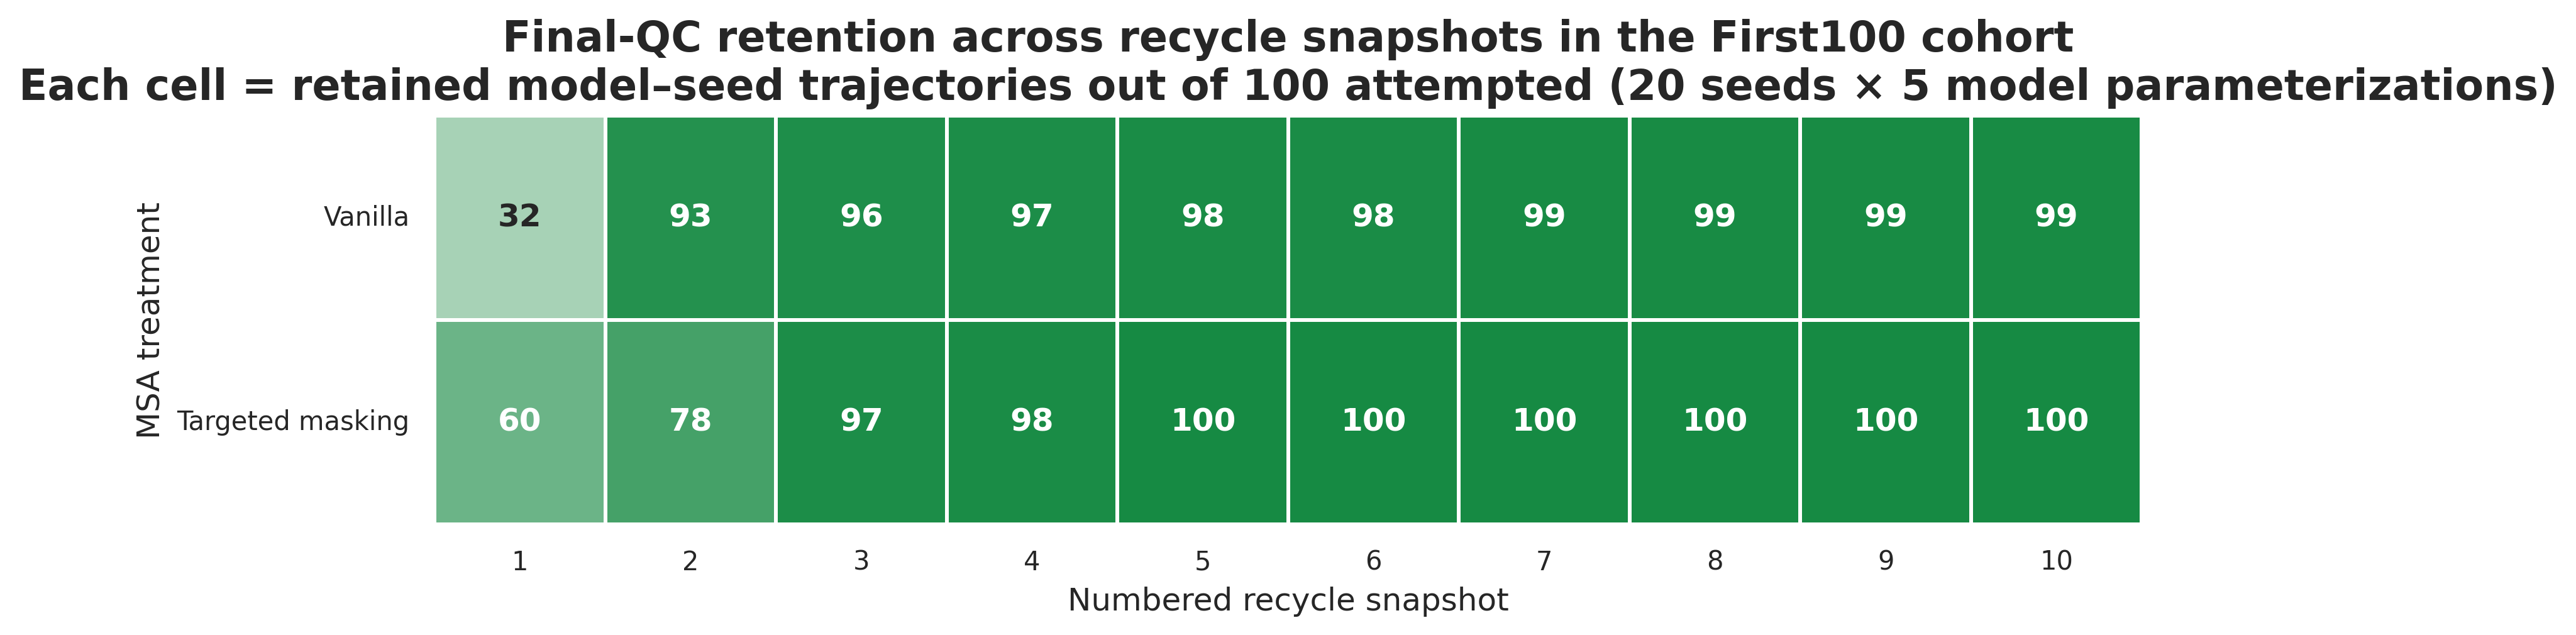

In [10]:
display(trajectory_retention_summary)
display(retention_test)
display(trajectory_retention_audit.loc[~trajectory_retention_audit['final_qc_retained']])
display(Image(filename=str(ALL_DISTANCE_FIG/'first100_nominal_trajectory_qc_audit.png')))

### Overall breadth and equal-retained-count statistical checks

,vanilla_seeds,masked_seeds,vanilla_median_normalized_seed_IQR,masked_median_normalized_seed_IQR,masked_over_vanilla_median_ratio,median_difference_masked_minus_vanilla,bootstrap_95CI_difference_low,bootstrap_95CI_difference_high,bootstrap_95CI_ratio_low,bootstrap_95CI_ratio_high,bootstrap_ratio_replicates,bootstrap_ratio_seed,mannwhitney_U_masked_vs_vanilla,mannwhitney_p_two_sided,rank_biserial_masked_greater
0,20,20,0.5,0.4,0.8,-0.1,-0.127115,-0.044312,0.758847,0.906061,10000,20260803,39.0,0.000014,-0.805


,iterations,retained_trajectories_per_protocol,median_IQR_ratio,IQR_ratio_95CI_low,IQR_ratio_95CI_high,median_fraction_distances_broader_masked,fraction_draws_median_IQR_ratio_gt_1
0,2000,99,0.75,0.75,0.75,0.320513,0.0


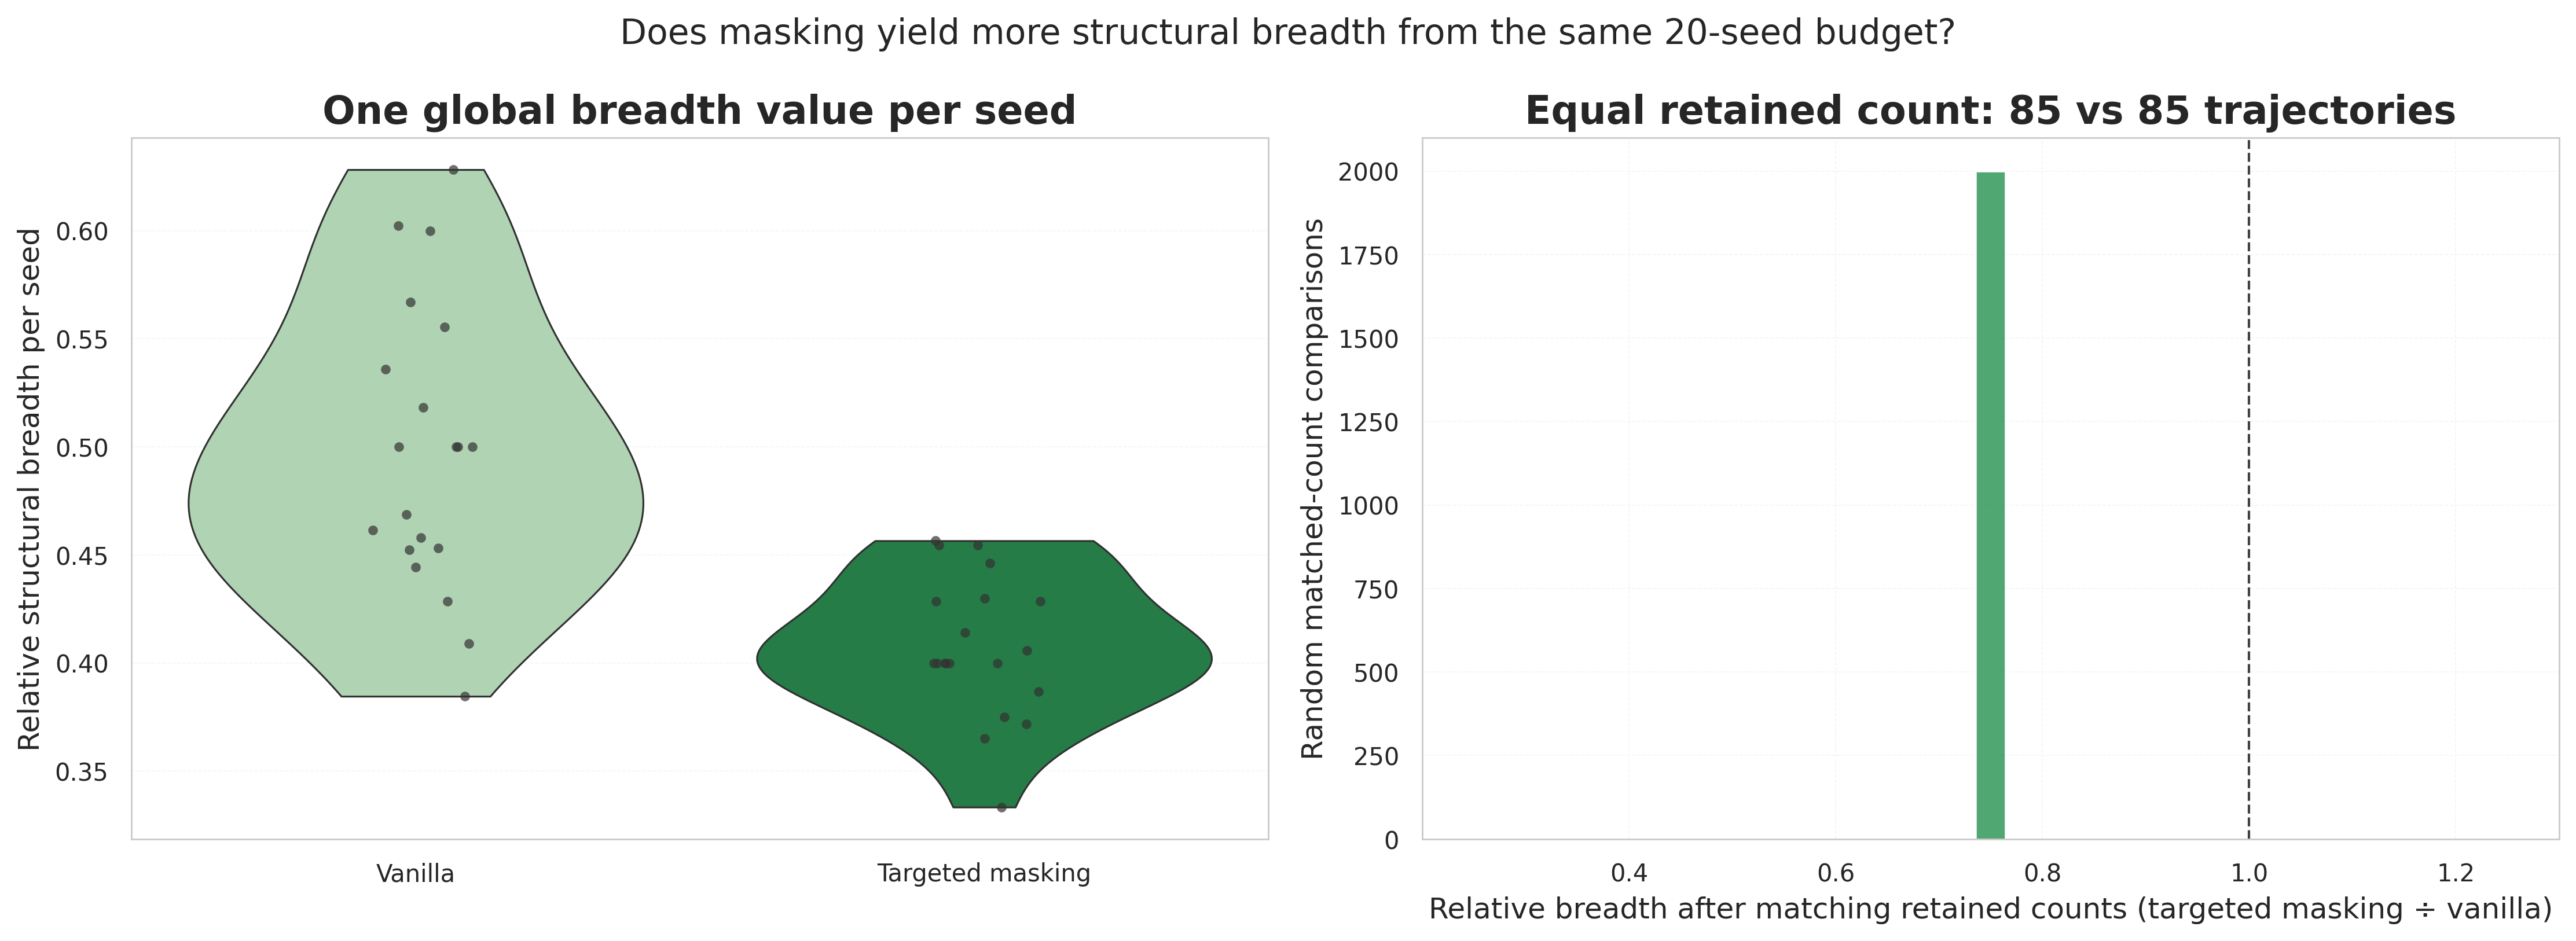

In [11]:
display(overall_seed_breadth_summary)
display(equal_count_rarefaction_summary)
display(Image(filename=str(ALL_DISTANCE_FIG/'first100_bang_for_buck_breadth_statistics.png')))

### First-100 distribution statistics using the standard W1 framework

,distances,CA_distances,shortest_heavy_distances,median_W1_A,median_normalized_W1,median_IQR_ratio_masked_over_vanilla,n_W1_q_lt_0.05,fraction_W1_q_lt_0.05,n_significant_broader_masked,n_significant_narrower_masked,n_directionally_broader_masked_q_lt_0.05,fraction_directionally_broader_masked_q_lt_0.05,n_permutations_per_distance,n_bootstrap_per_distance,permutation_unit,bootstrap_unit
0,546,273,273,0.503181,0.948164,0.75,537,0.983516,172,348,114,0.208791,999,500,seed block,seed block


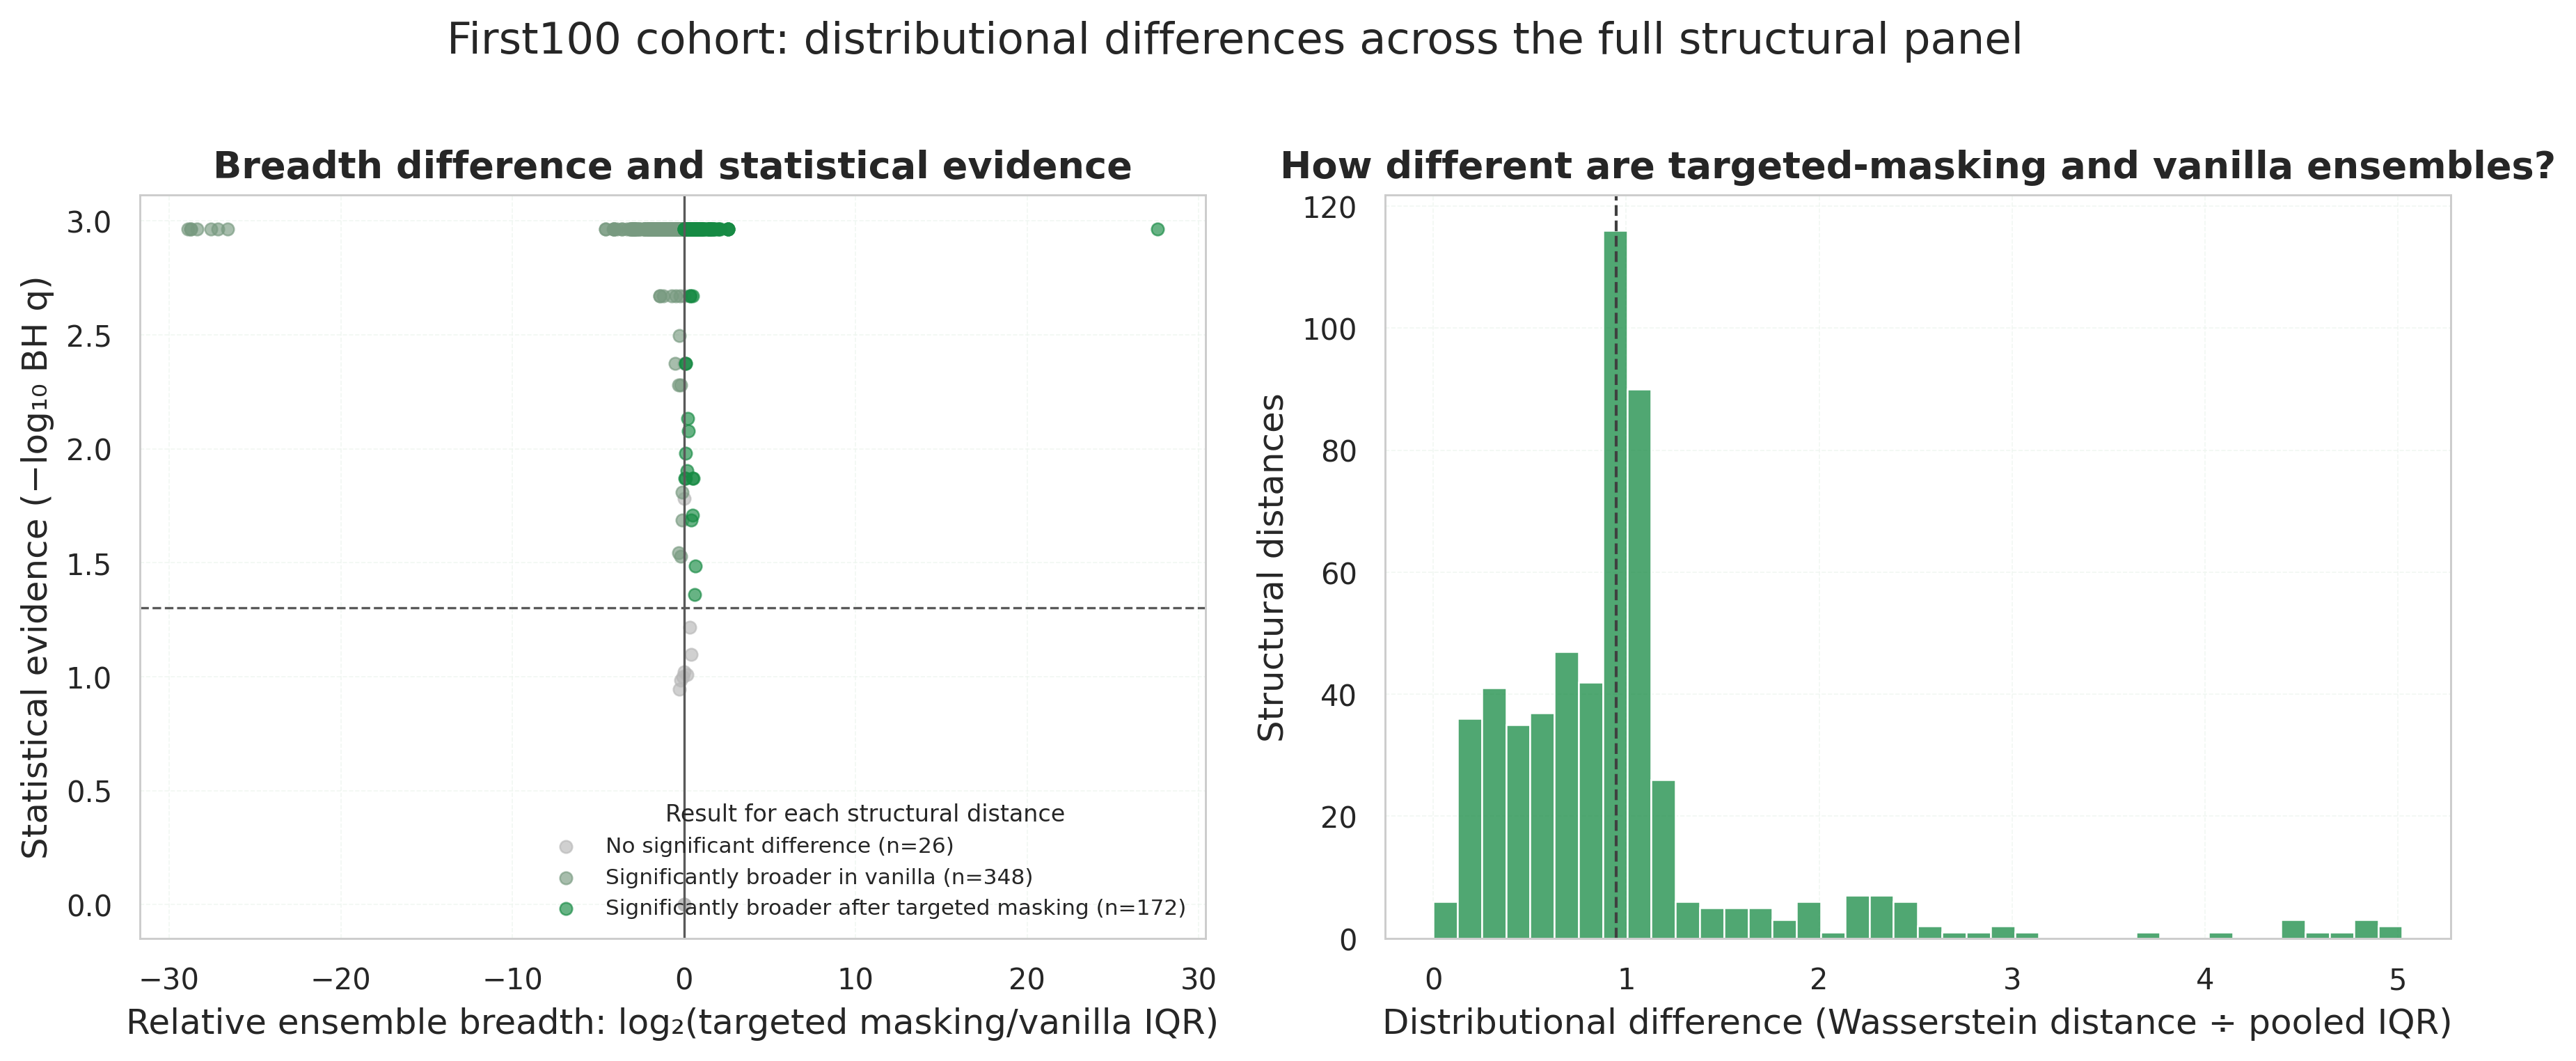

In [12]:
display(first100_distribution_statistics_summary)
display(Image(filename=str(ALL_DISTANCE_FIG/'first100_seed_block_distribution_statistics.png')))

### First-100 headline figures: breadth gained per fixed sampling budget

The four-panel summary separates the main claims: one breadth value per independent seed; the distribution of breadth effects across all 546 chain-label-safe intrachain distances; the direct one-sided seed-block permutation result after BH-FDR; and final-QC retention from the same 100 nominal trajectories. The compact evidence map orders all distances from narrower to broader and marks those with direct statistical support for masked broadening.

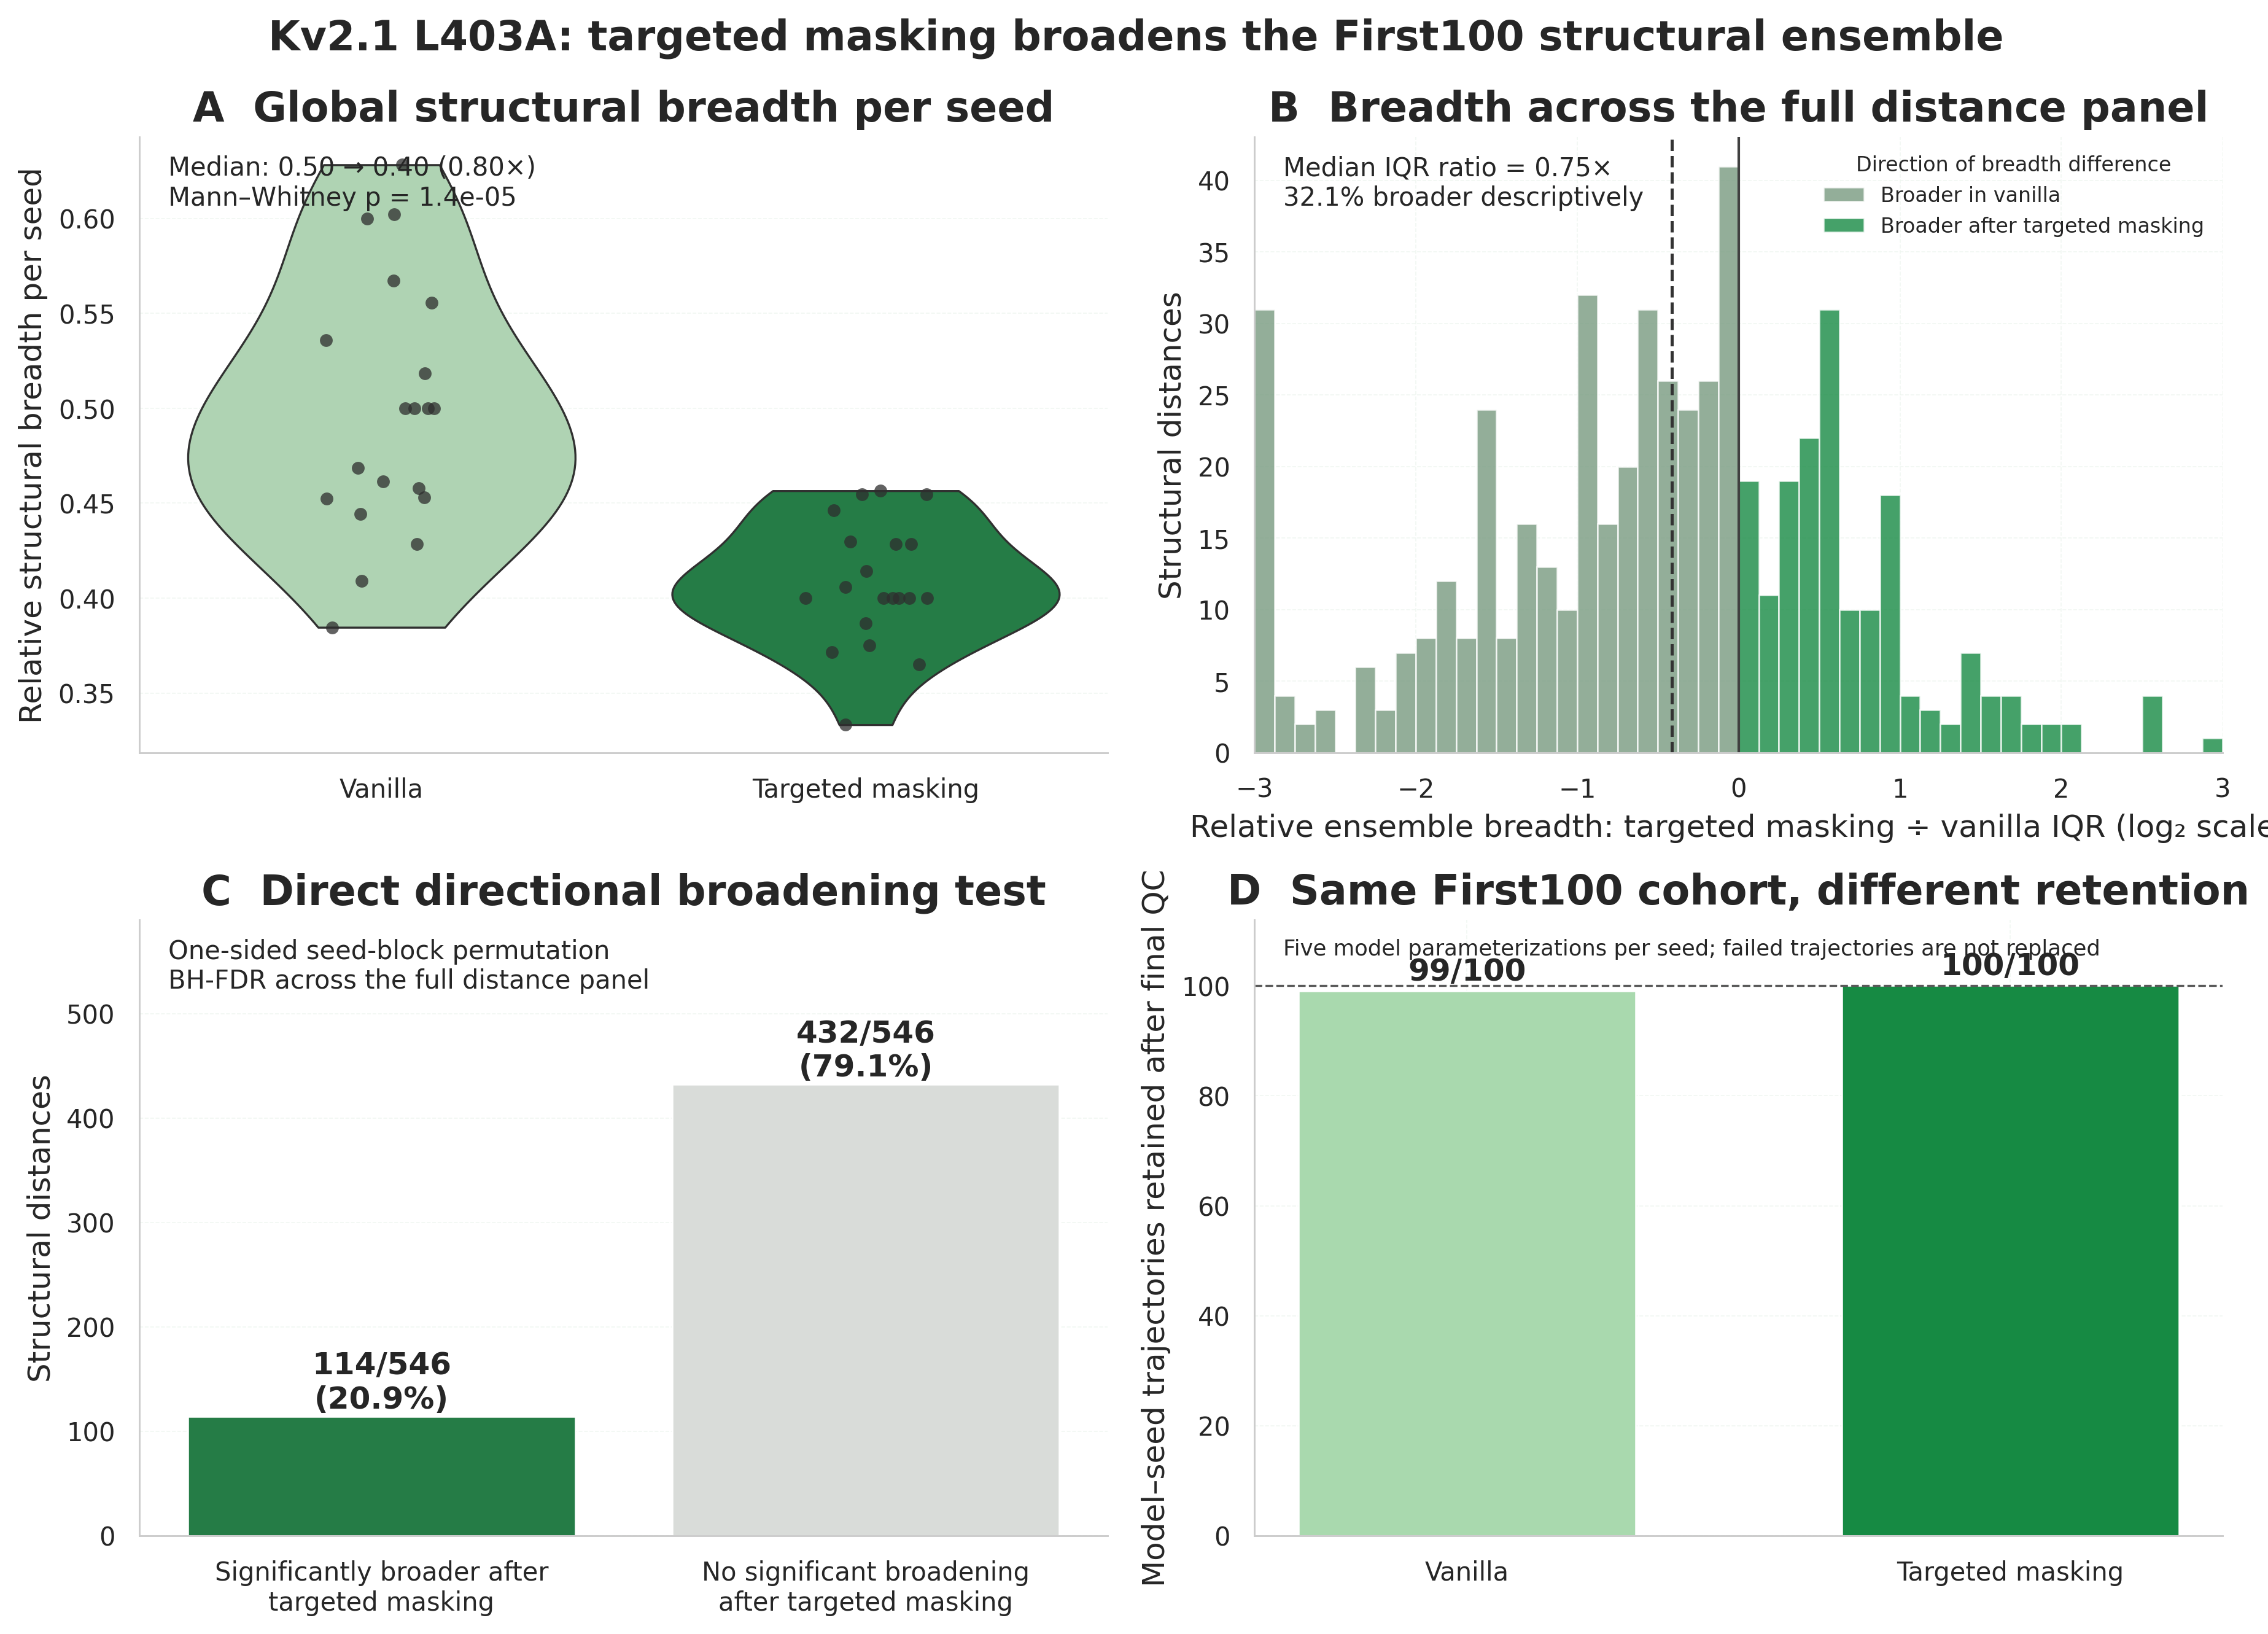

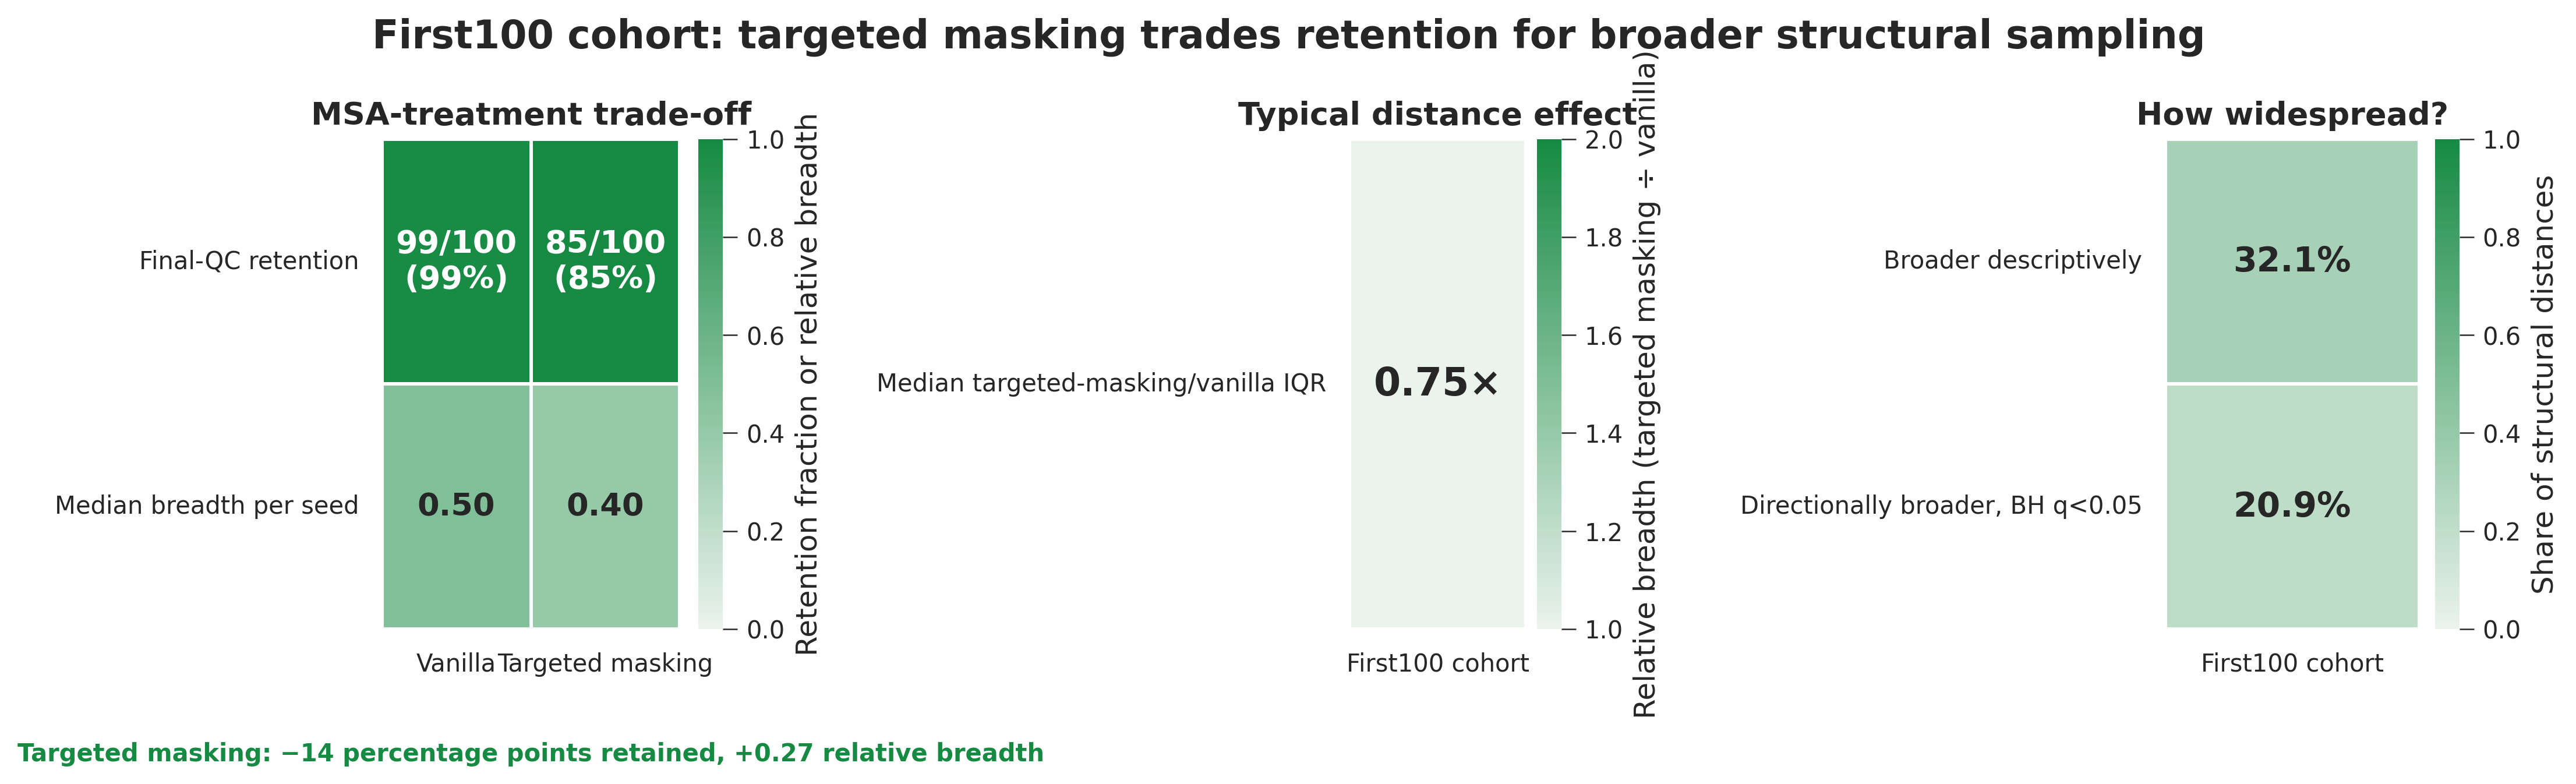

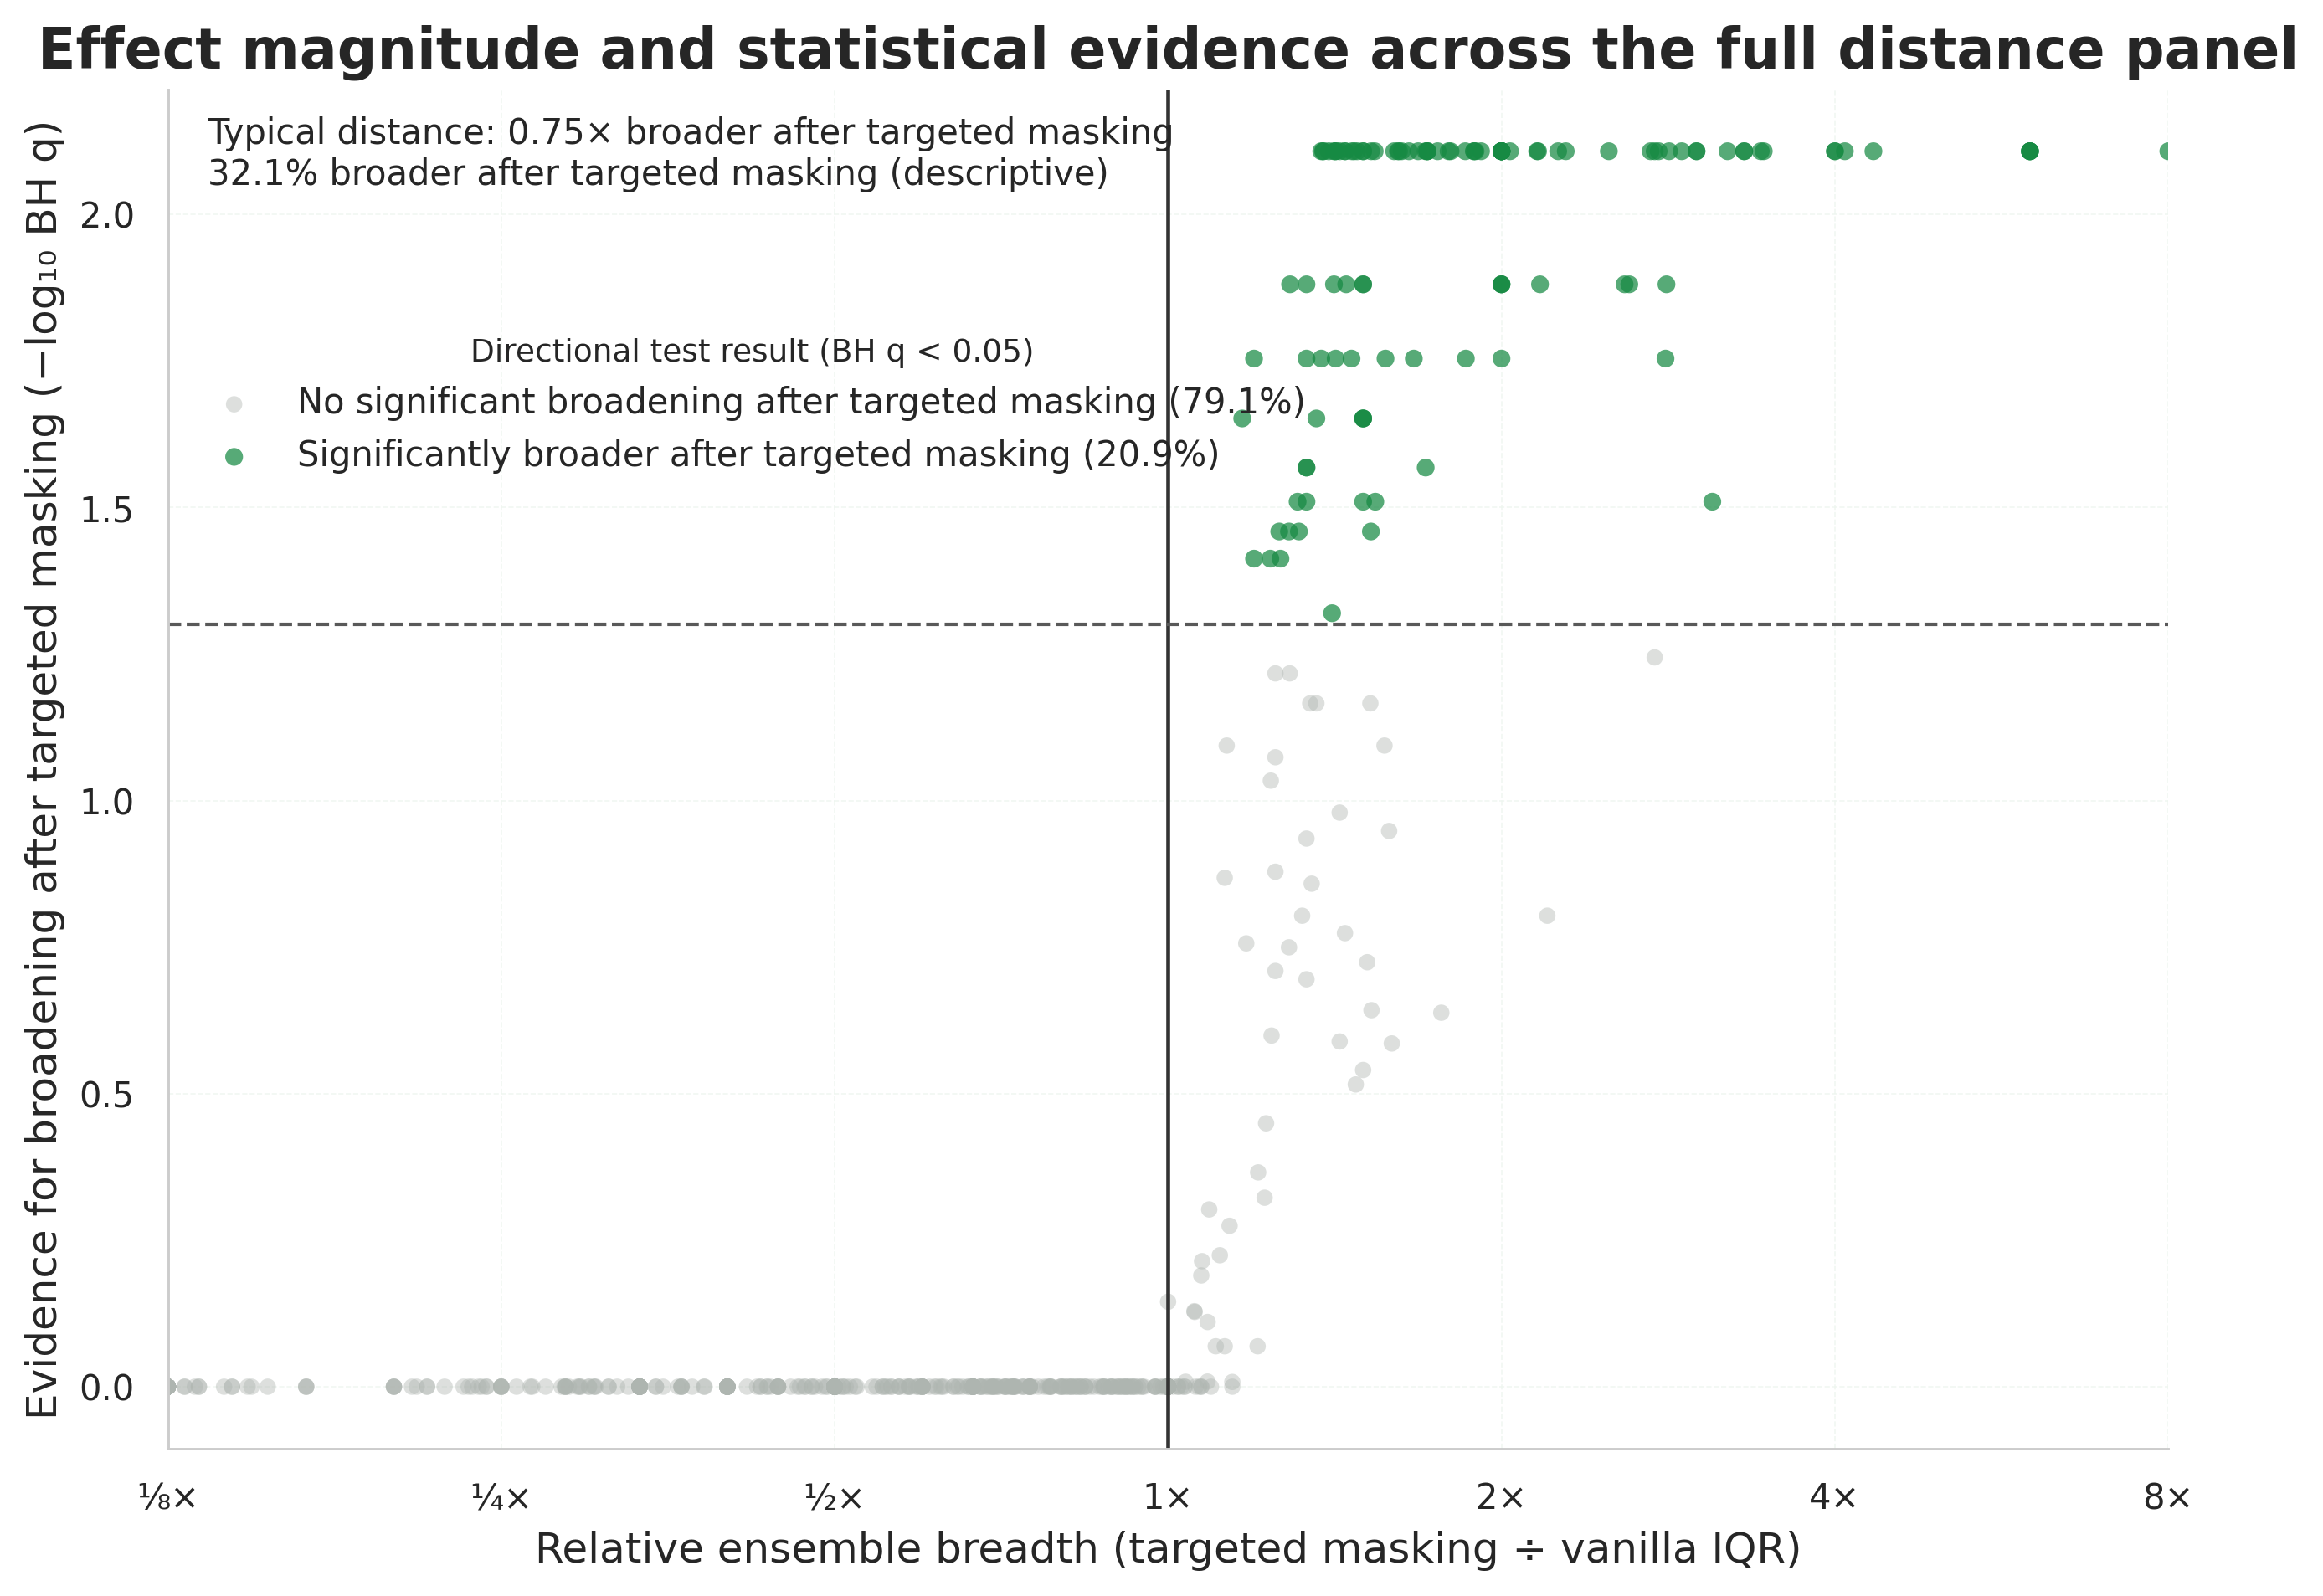

In [13]:
display(Image(filename=str(ALL_DISTANCE_FIG/'first100_masked_sampling_breadth_main_summary.png')))
display(Image(filename=str(ALL_DISTANCE_FIG/'first100_retention_vs_breadth_heatmap_scorecard.png')))
display(Image(filename=str(ALL_DISTANCE_FIG/'first100_all_distance_breadth_evidence_map.png')))

### Direct statistical test of broader distributions: first 100 versus full QC

For each chain-label-safe intrachain distance, the directional null is tested by permuting complete seed blocks between protocols. The one-sided alternative is `IQR(masked) > IQR(vanilla)`. Benjamini–Hochberg correction is applied across all 546 distances separately within each cohort. This is the direct broadening test; W1 above tests any distributional separation and is not itself directional.

,distances,CA_distances,shortest_heavy_distances,median_W1_A,median_normalized_W1,median_IQR_ratio_masked_over_vanilla,n_W1_q_lt_0.05,fraction_W1_q_lt_0.05,n_significant_broader_masked,n_significant_narrower_masked,n_directionally_broader_masked_q_lt_0.05,fraction_directionally_broader_masked_q_lt_0.05,n_permutations_per_distance,n_bootstrap_per_distance,permutation_unit,bootstrap_unit,cohort
0,546,273,273,0.503181,0.948164,0.75,537,0.983516,172,348,114,0.208791,999,500,seed block,seed block,Nominal first 100
1,546,273,273,0.418415,0.911698,0.70,540,0.989011,165,347,139,0.254579,999,500,seed block,seed block,Full QC


,distance,distance_type_first100,vanilla_trajectories_first100,masked_trajectories_first100,cohort_first100,vanilla_seeds_first100,masked_seeds_first100,vanilla_median_A_first100,masked_median_A_first100,delta_median_A_first100,...,W1_CI_high_A_full,delta_median_CI_low_A_full,delta_median_CI_high_A_full,log2_IQR_ratio_CI_low_full,log2_IQR_ratio_CI_high_full,n_permutations_full,n_bootstrap_full,q_W1_seed_block_BH_full,q_broader_masked_seed_block_BH_full,min_broadening
8,CA_CA_A_ARG291_CA-A_GLU241_CA,CA,99,100,first100,20,20,30.02,30.215,0.195,...,0.219551,0.190000,0.210000,0.684630,1.070389,999,500,0.001026,0.00455,0.750022
15,CA_CA_A_ARG292_CA-A_GLU231_CA,CA,99,100,first100,20,20,21.28,21.610,0.330,...,0.281646,0.320000,0.350000,0.895161,1.129283,999,500,0.001026,0.00455,0.619728
29,CA_CA_A_ARG301_CA-A_CYS234_CA,CA,99,100,first100,20,20,12.19,12.190,0.000,...,0.029647,-0.007625,0.010000,0.567041,1.000000,999,500,0.001026,0.00455,0.772589
31,CA_CA_A_ARG301_CA-A_GLU231_CA,CA,99,100,first100,20,20,10.44,10.540,0.100,...,0.105061,0.095000,0.110000,1.321928,1.678072,999,500,0.001026,0.00455,1.415037
34,CA_CA_A_ARG301_CA-A_PHE238_CA,CA,99,100,first100,20,20,12.97,12.870,-0.100,...,0.090016,-0.110000,-0.100000,0.753887,1.459432,999,500,0.001026,0.00455,1.137504
37,CA_CA_A_ARG304_CA-A_CYS234_CA,CA,99,100,first100,20,20,10.63,10.585,-0.045,...,0.083058,-0.060000,-0.050000,1.654249,2.140760,999,500,0.001026,0.00455,1.847997
39,CA_CA_A_ARG304_CA-A_GLU231_CA,CA,99,100,first100,20,20,11.29,11.270,-0.020,...,0.048001,-0.030000,-0.030000,0.700440,1.099536,999,500,0.001026,0.00455,1.000000
42,CA_CA_A_ARG304_CA-A_PHE238_CA,CA,99,100,first100,20,20,9.85,9.795,-0.055,...,0.048501,-0.070000,-0.050000,0.830075,1.352986,999,500,0.001026,0.00455,0.917538
44,CA_CA_A_ARG310_CA-A_ASP264_CA,CA,99,100,first100,20,20,9.12,9.000,-0.120,...,0.115213,-0.120000,-0.110000,0.447459,0.878009,999,500,0.001026,0.00455,0.608809
63,CA_CA_A_LYS429_CA-A_ASN181_CA,CA,99,100,first100,20,20,10.64,10.910,0.270,...,1.448234,0.247375,0.400000,-0.142481,0.905764,999,500,0.001026,0.00455,0.530515


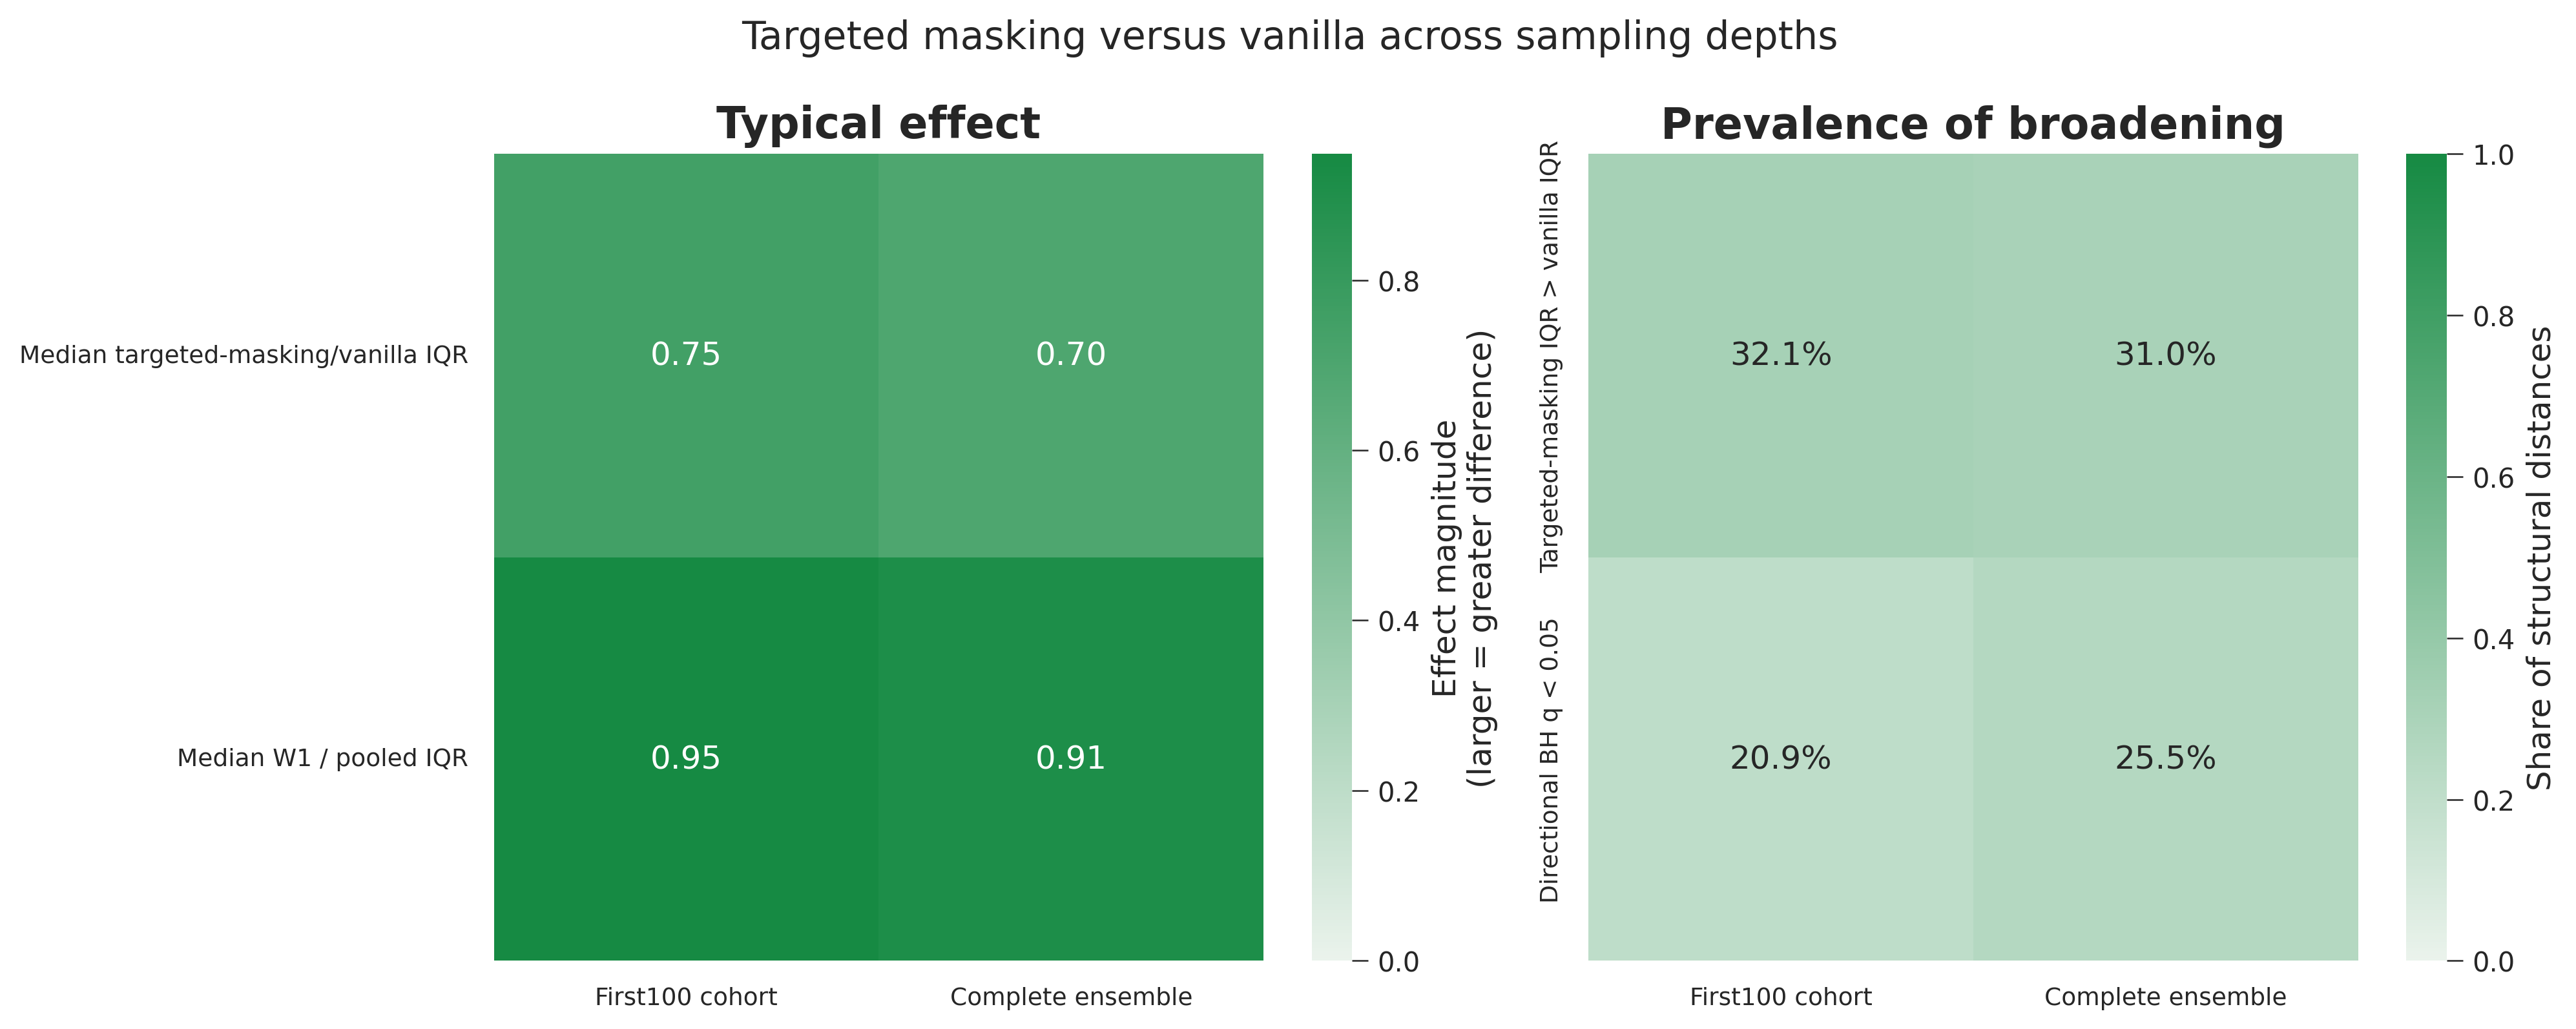

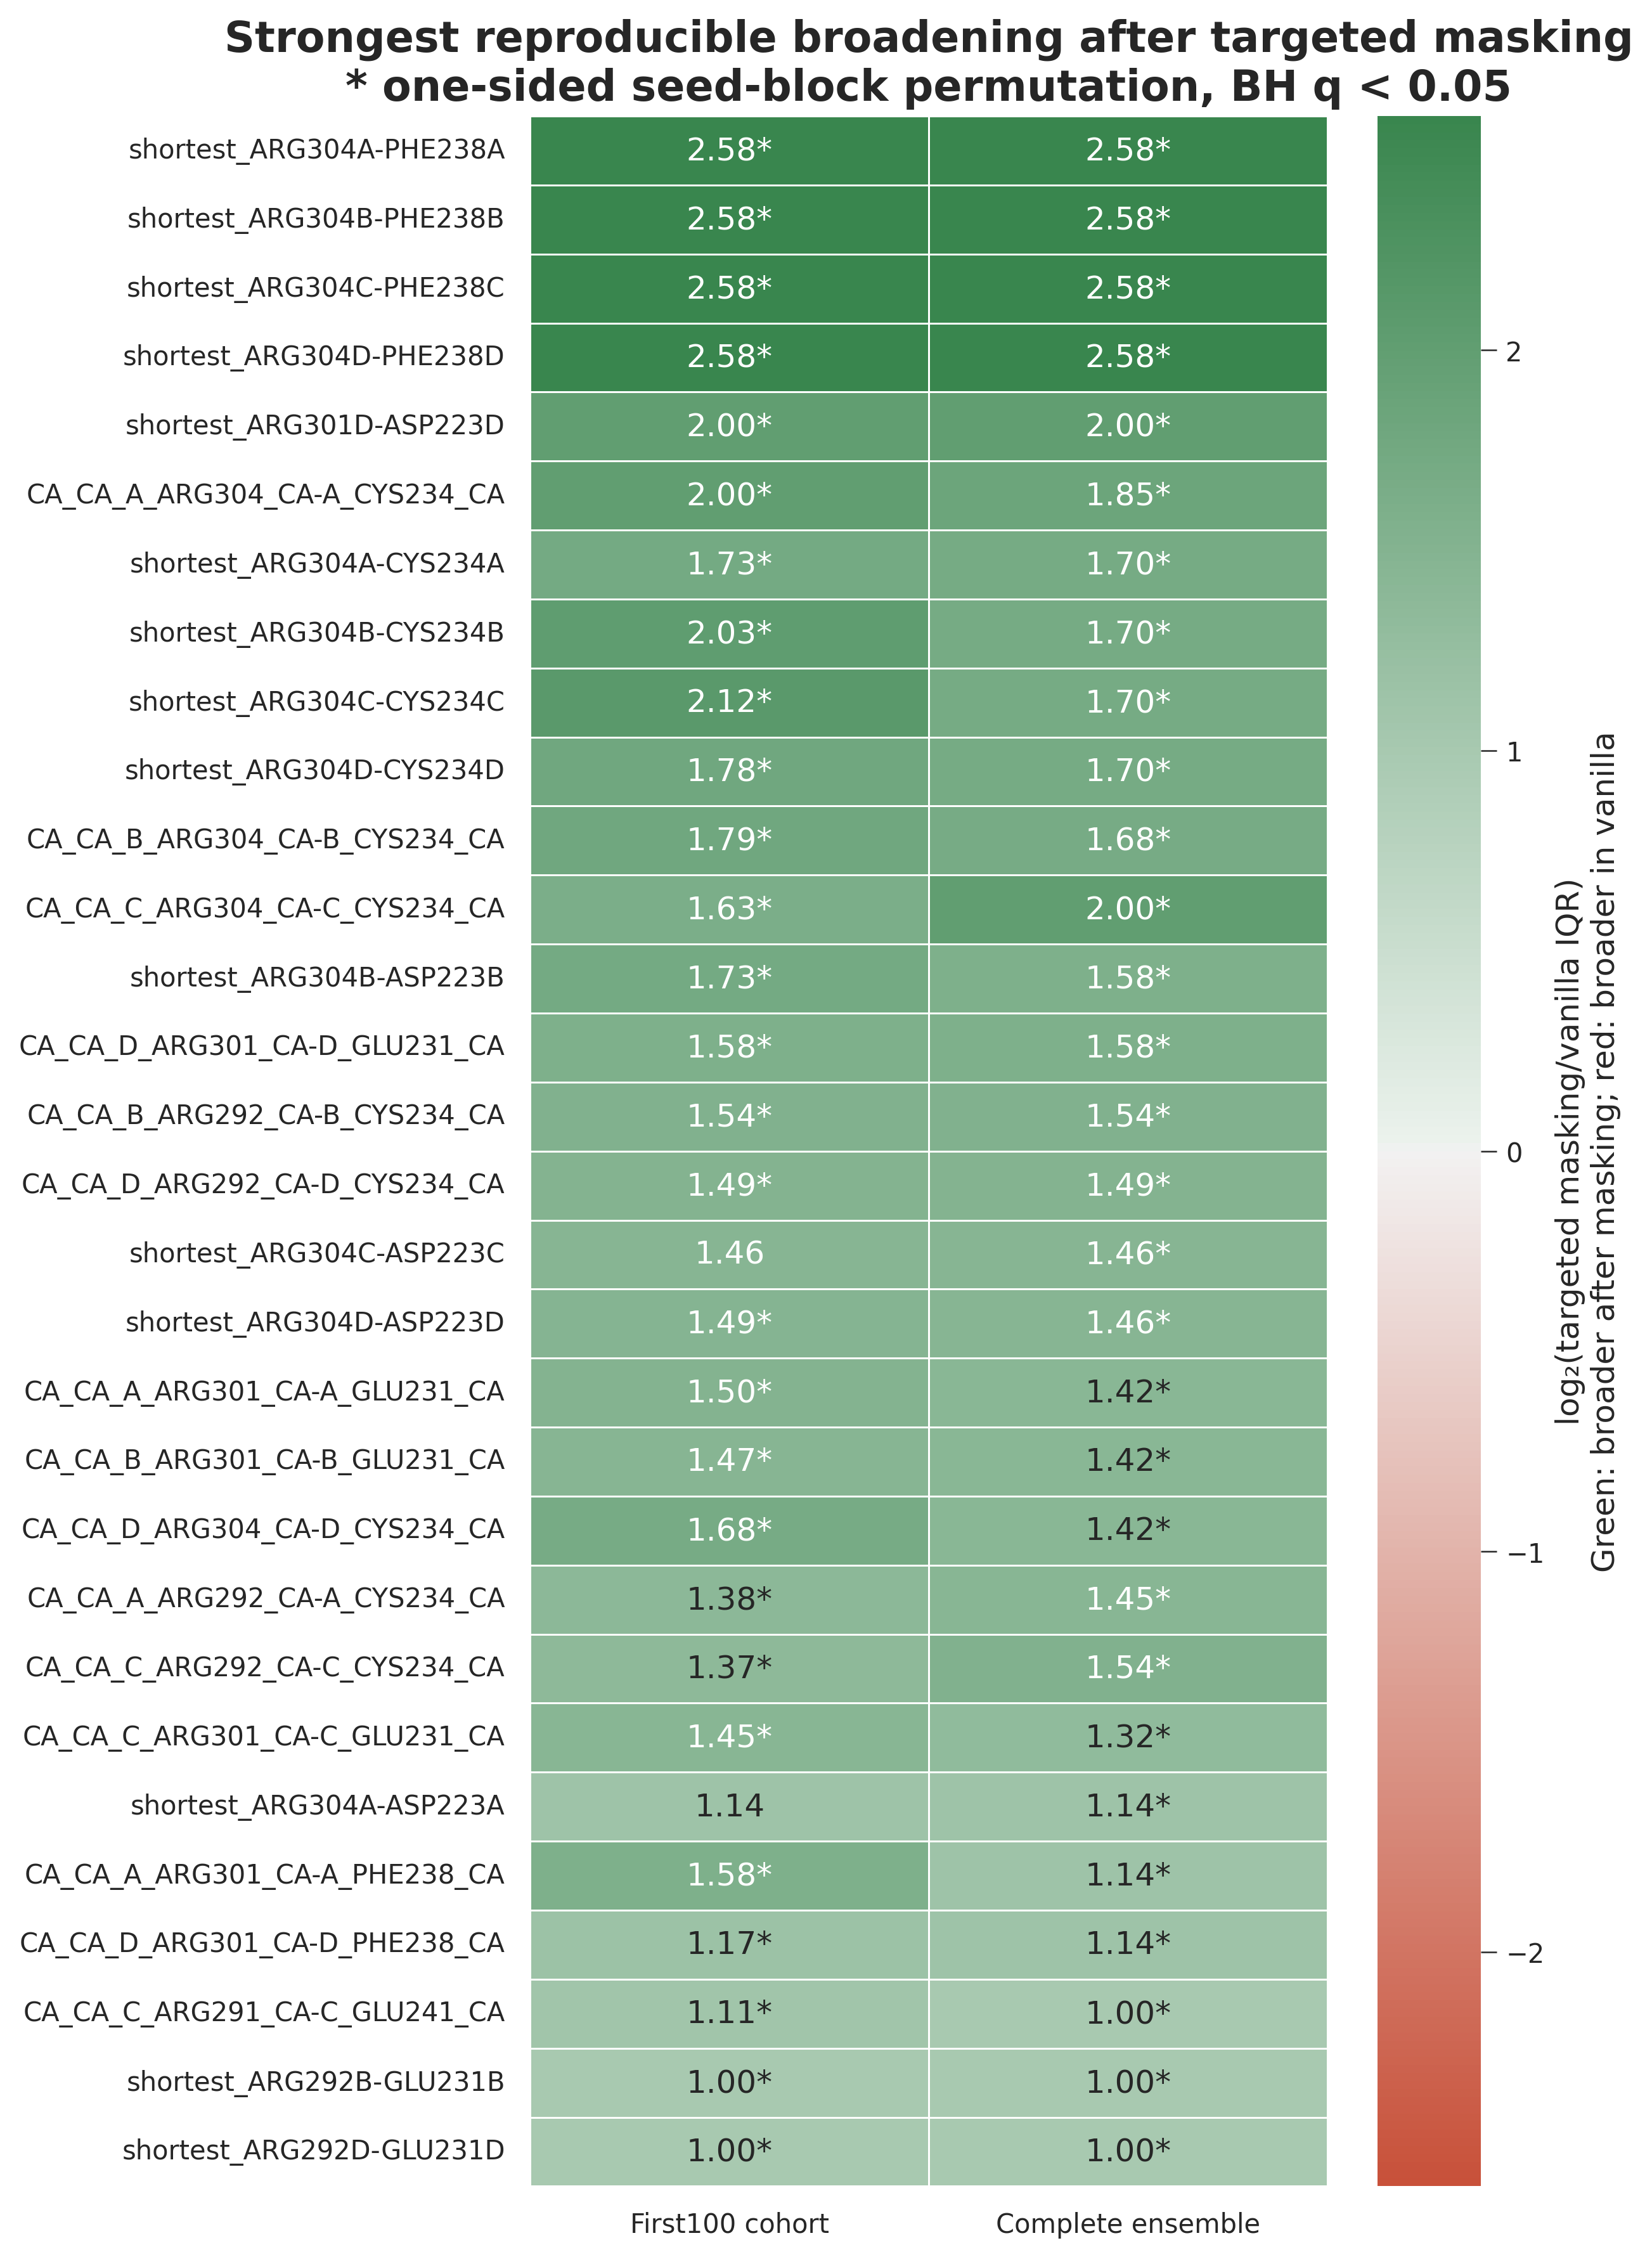

In [14]:
display(pd.concat([
    first100_distribution_statistics_summary.assign(cohort='Nominal first 100'),
    full_distribution_statistics_summary.assign(cohort='Full QC')
], ignore_index=True))
display(first100_vs_full_directional_statistics.sort_values(
    ['q_broader_masked_seed_block_BH_first100','q_broader_masked_seed_block_BH_full']
).head(30))
display(Image(filename=str(ALL_DISTANCE_FIG/'first100_vs_full_breadth_summary_heatmaps.png')))
display(Image(filename=str(ALL_DISTANCE_FIG/'first100_vs_full_directional_breadth_heatmap.png')))

### Clear reproducibility views

The first heatmap counts distances according to whether the direct masked-broadening test is significant in the first-100 and full-QC cohorts. The scatter then shows the effect magnitude for every distance: upper-right points are broader under masking in both analyses, and points near the diagonal have similar early and full effects. The final heatmaps separate Cα and shortest-heavy distances to show whether the conclusion depends on the distance definition.

,Not broader,"Broader, q < 0.05"
Not broader,397,35
"Broader, q < 0.05",10,104


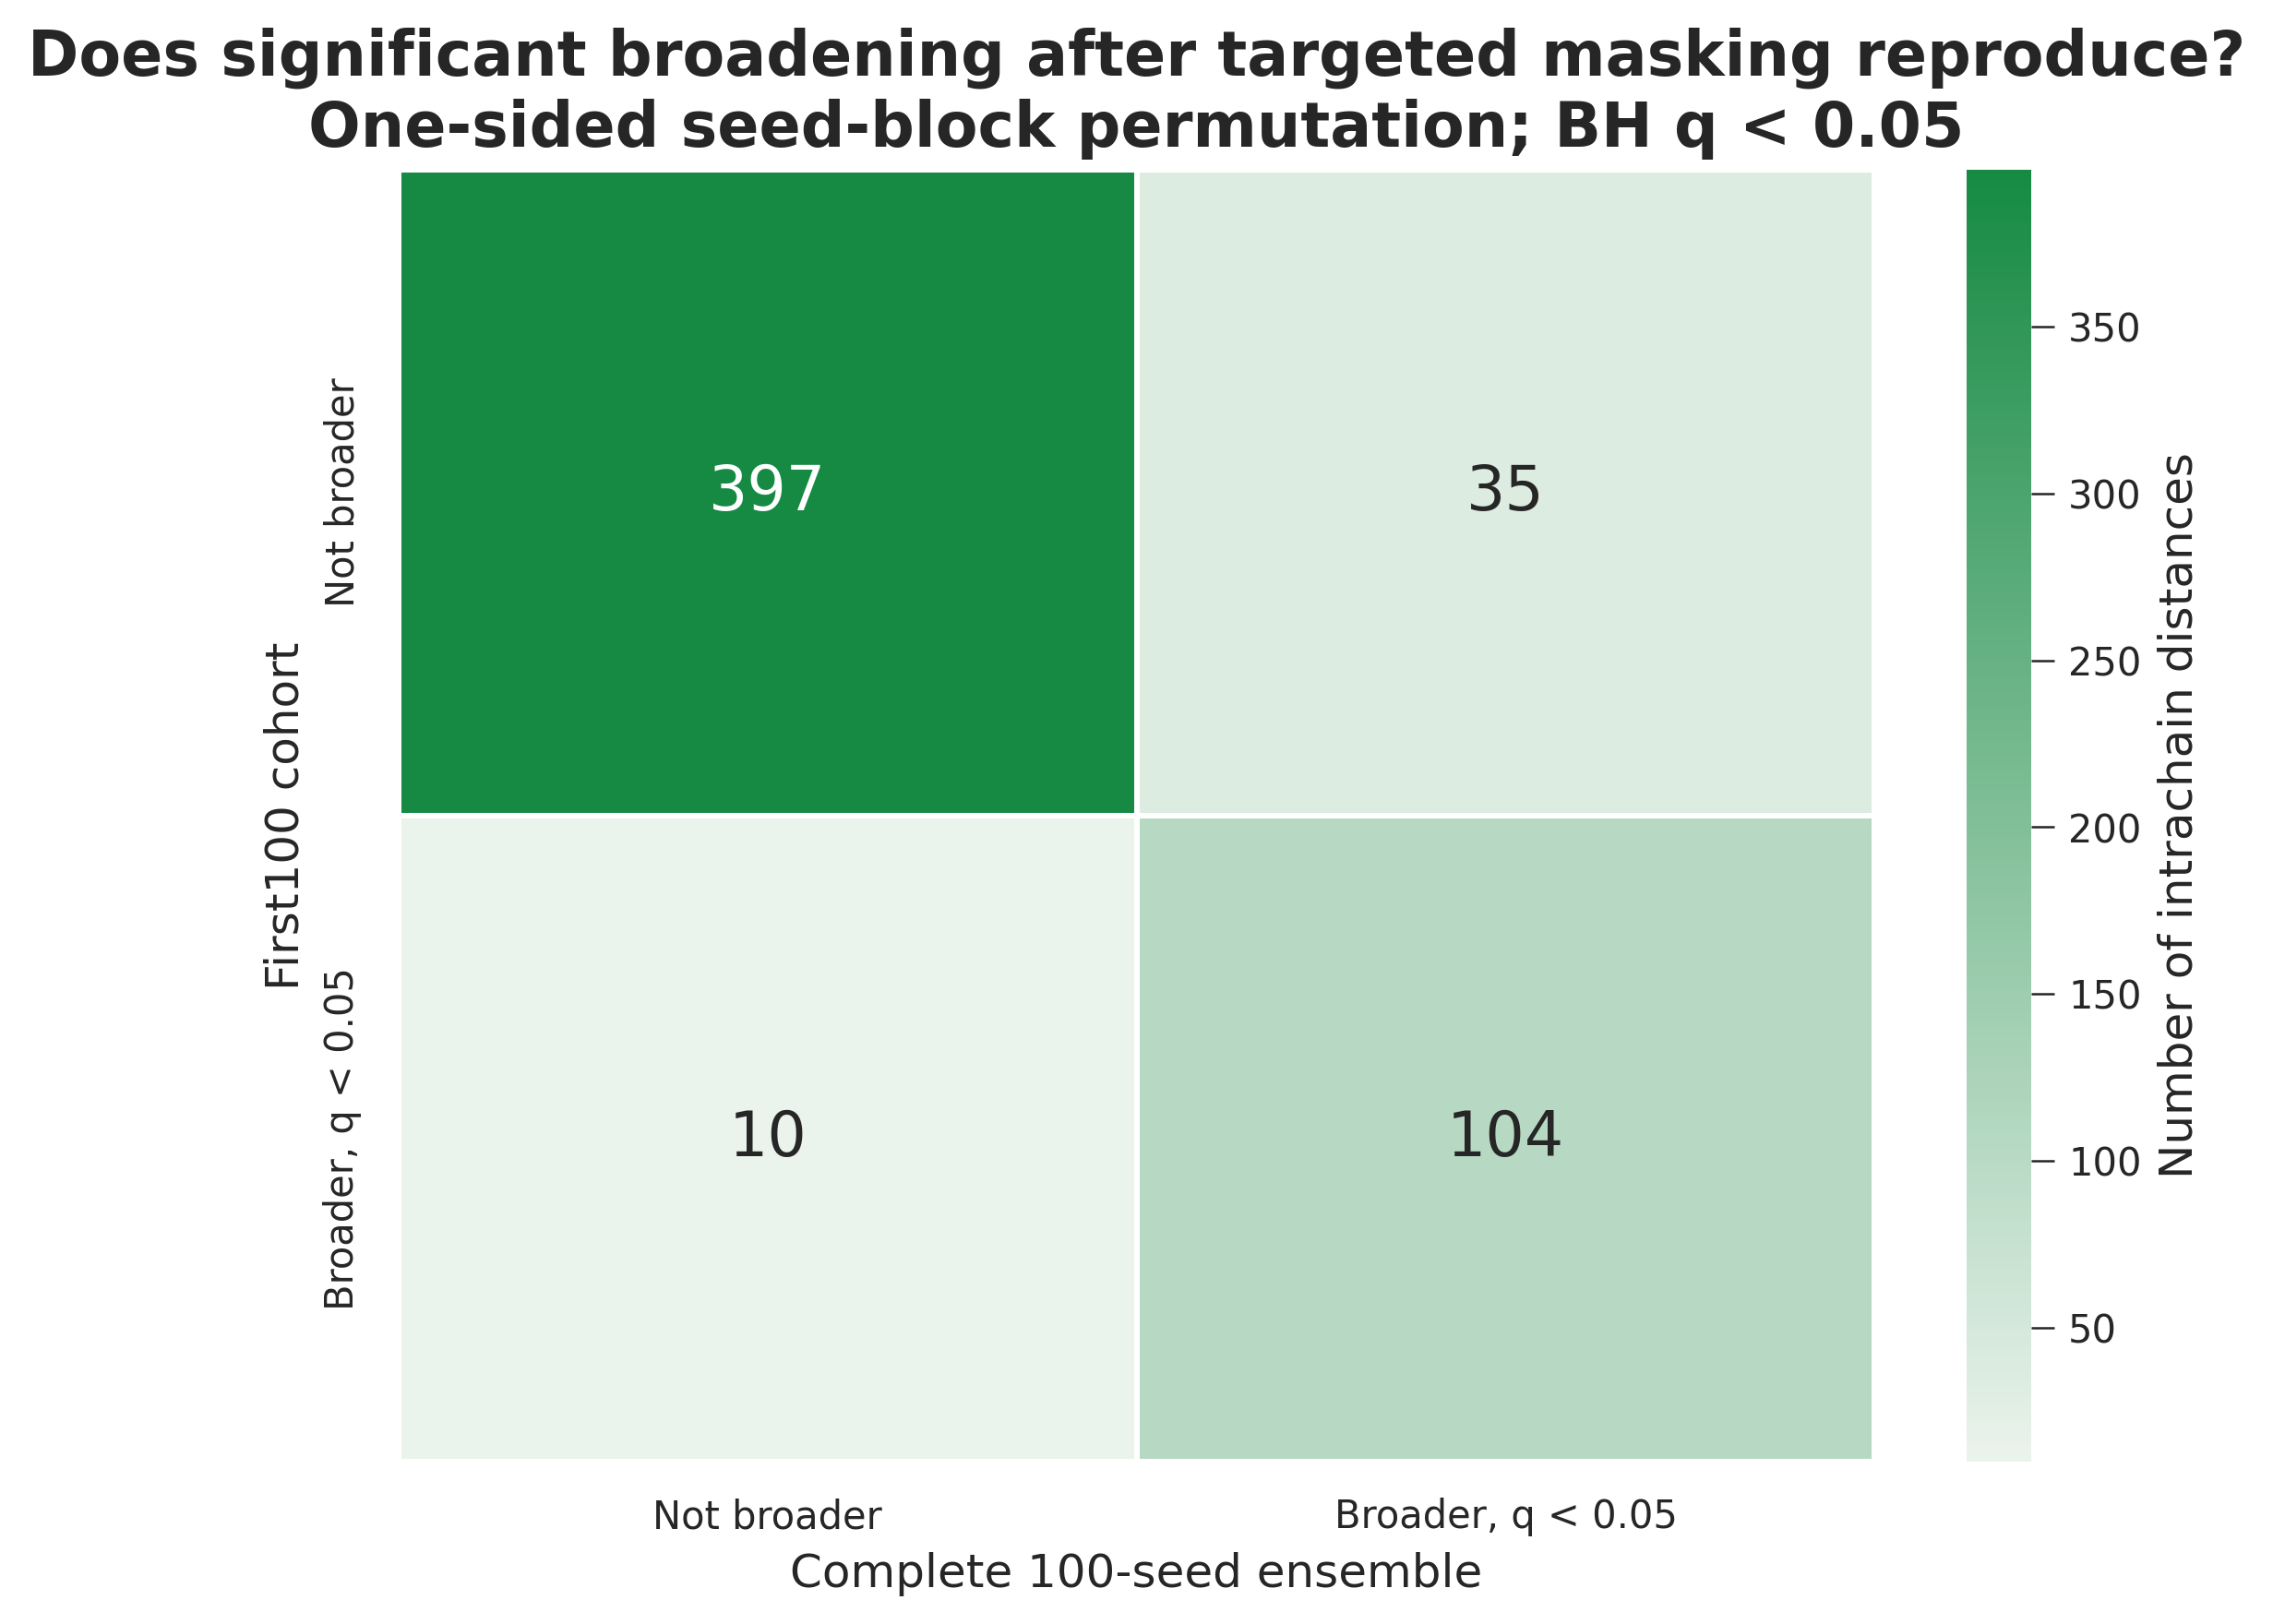

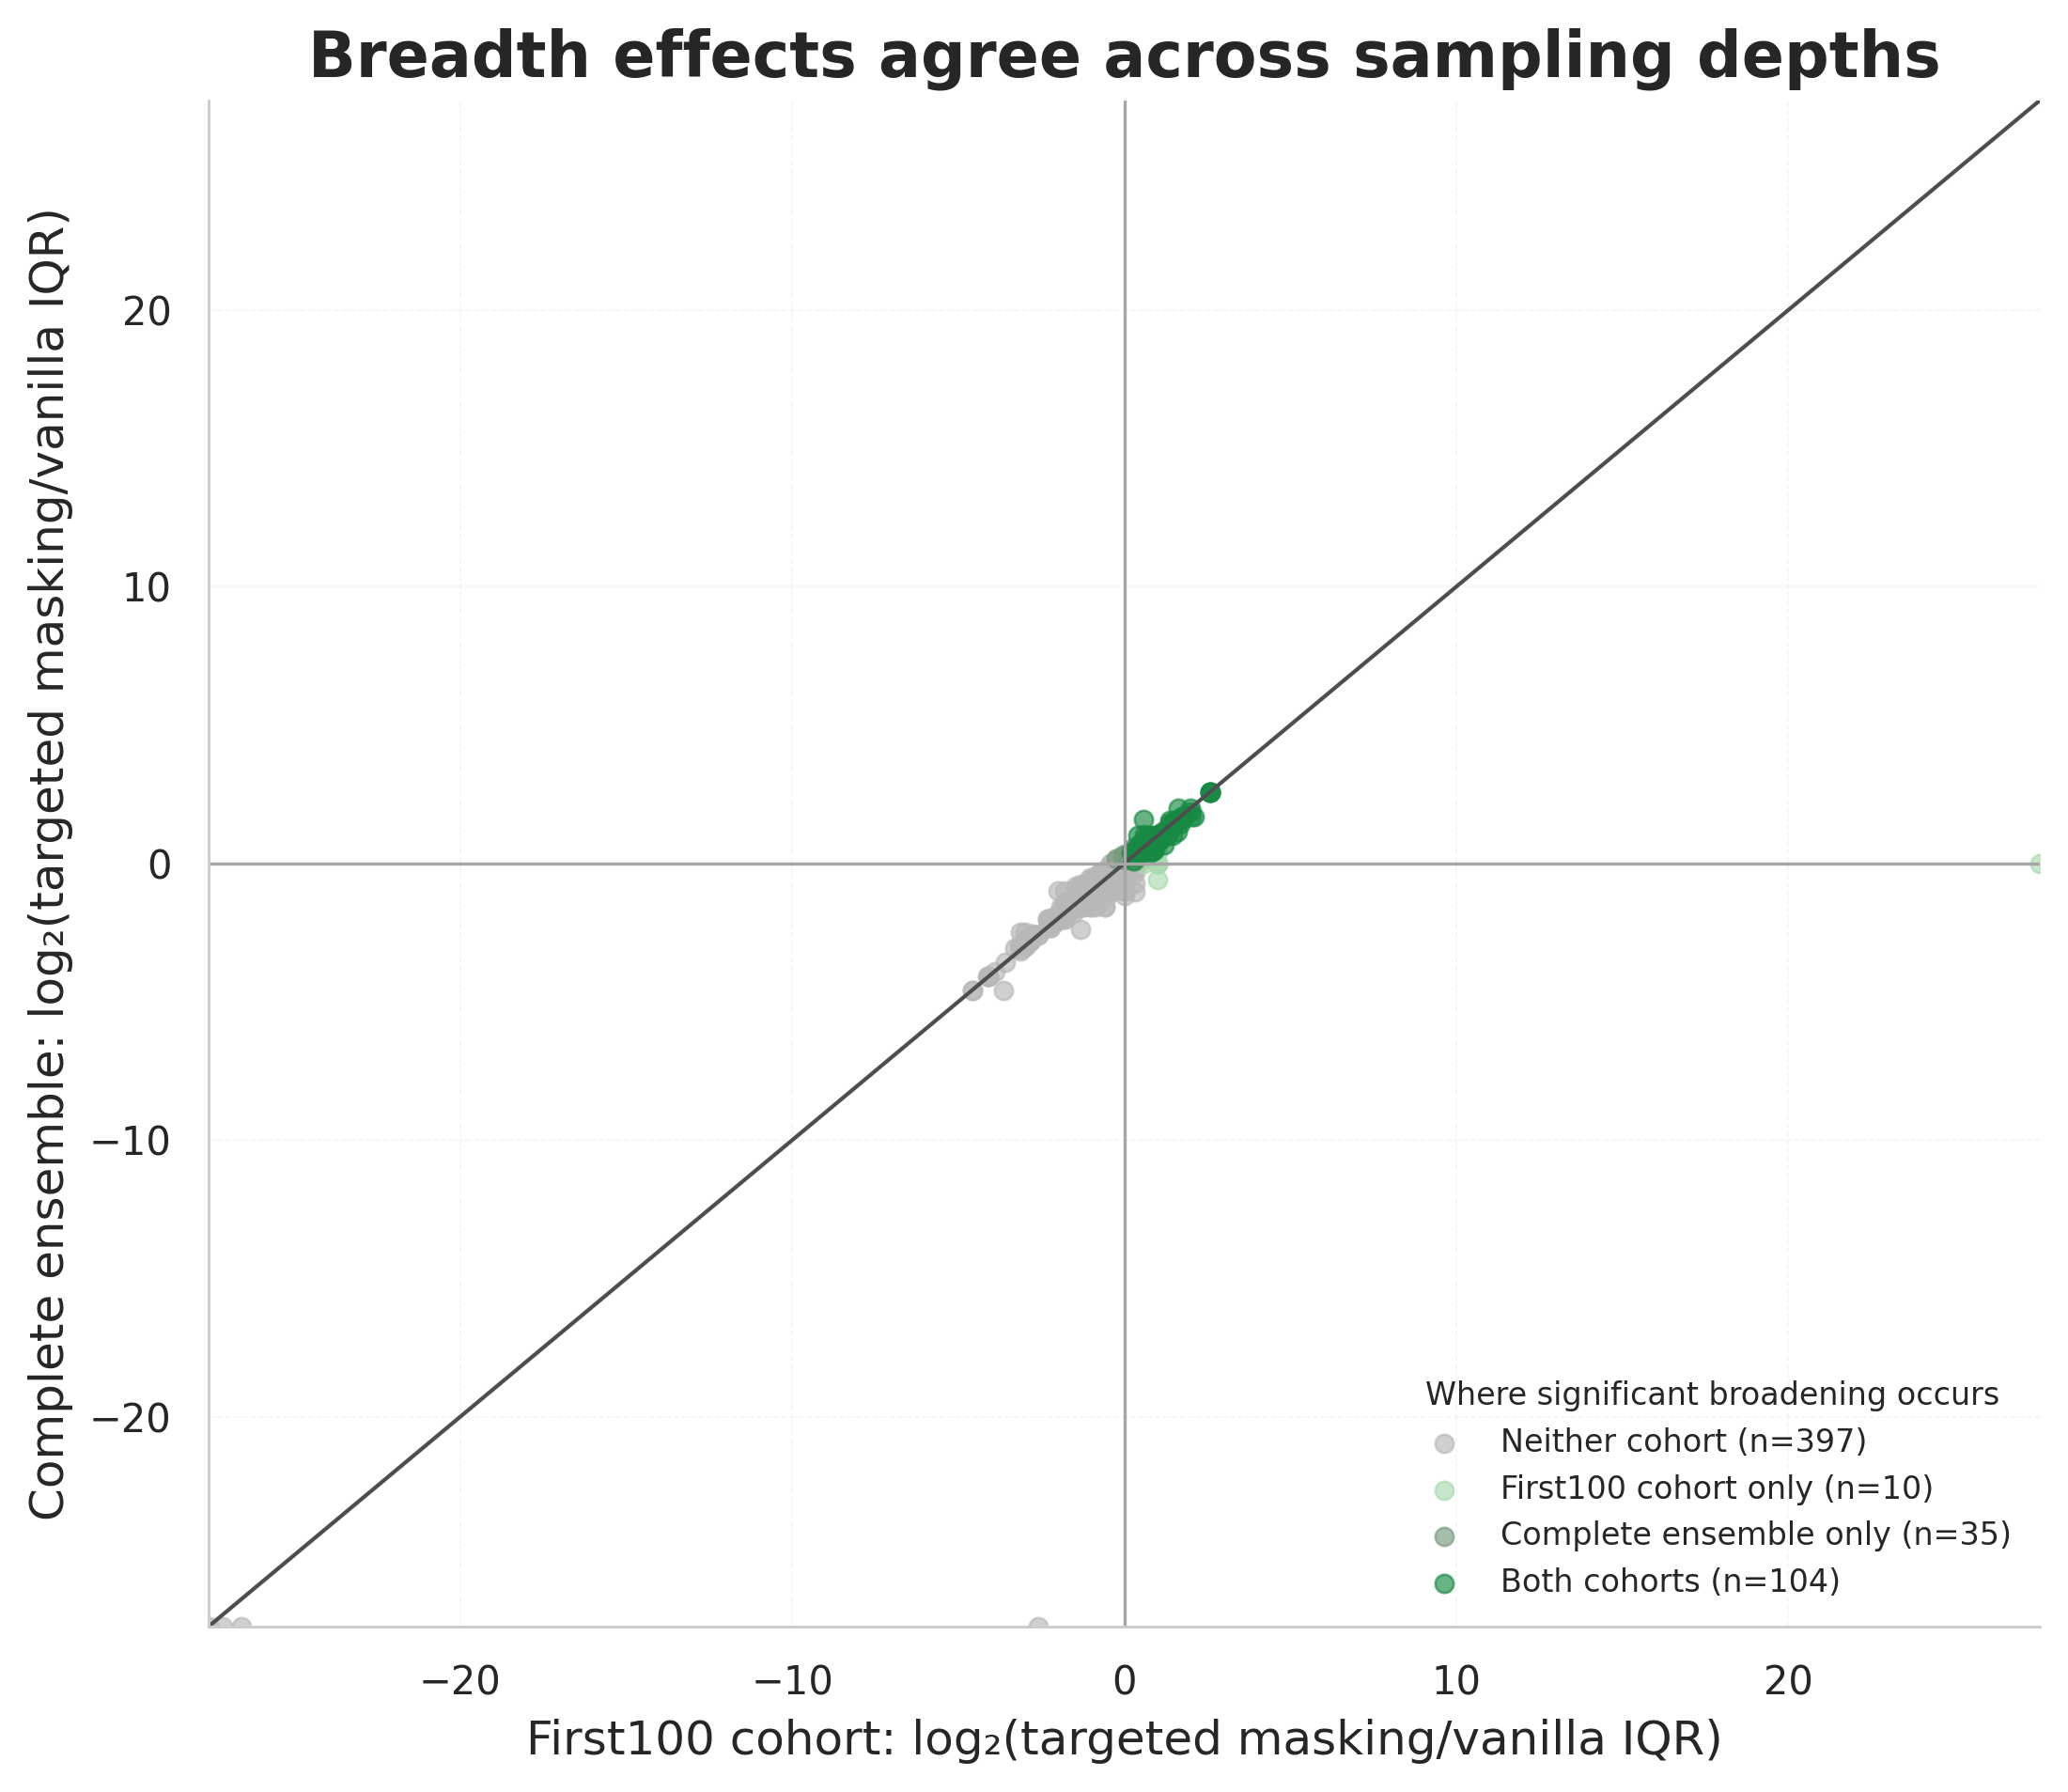

,cohort,distance_type,median_IQR_ratio,fraction_broader,fraction_significantly_broader
0,Nominal first 100,Cα,0.916667,0.417582,0.241758
1,Nominal first 100,Shortest-heavy,0.500000,0.223443,0.175824
2,Full QC,Cα,0.900000,0.413919,0.326007
3,Full QC,Shortest-heavy,0.500000,0.205128,0.183150


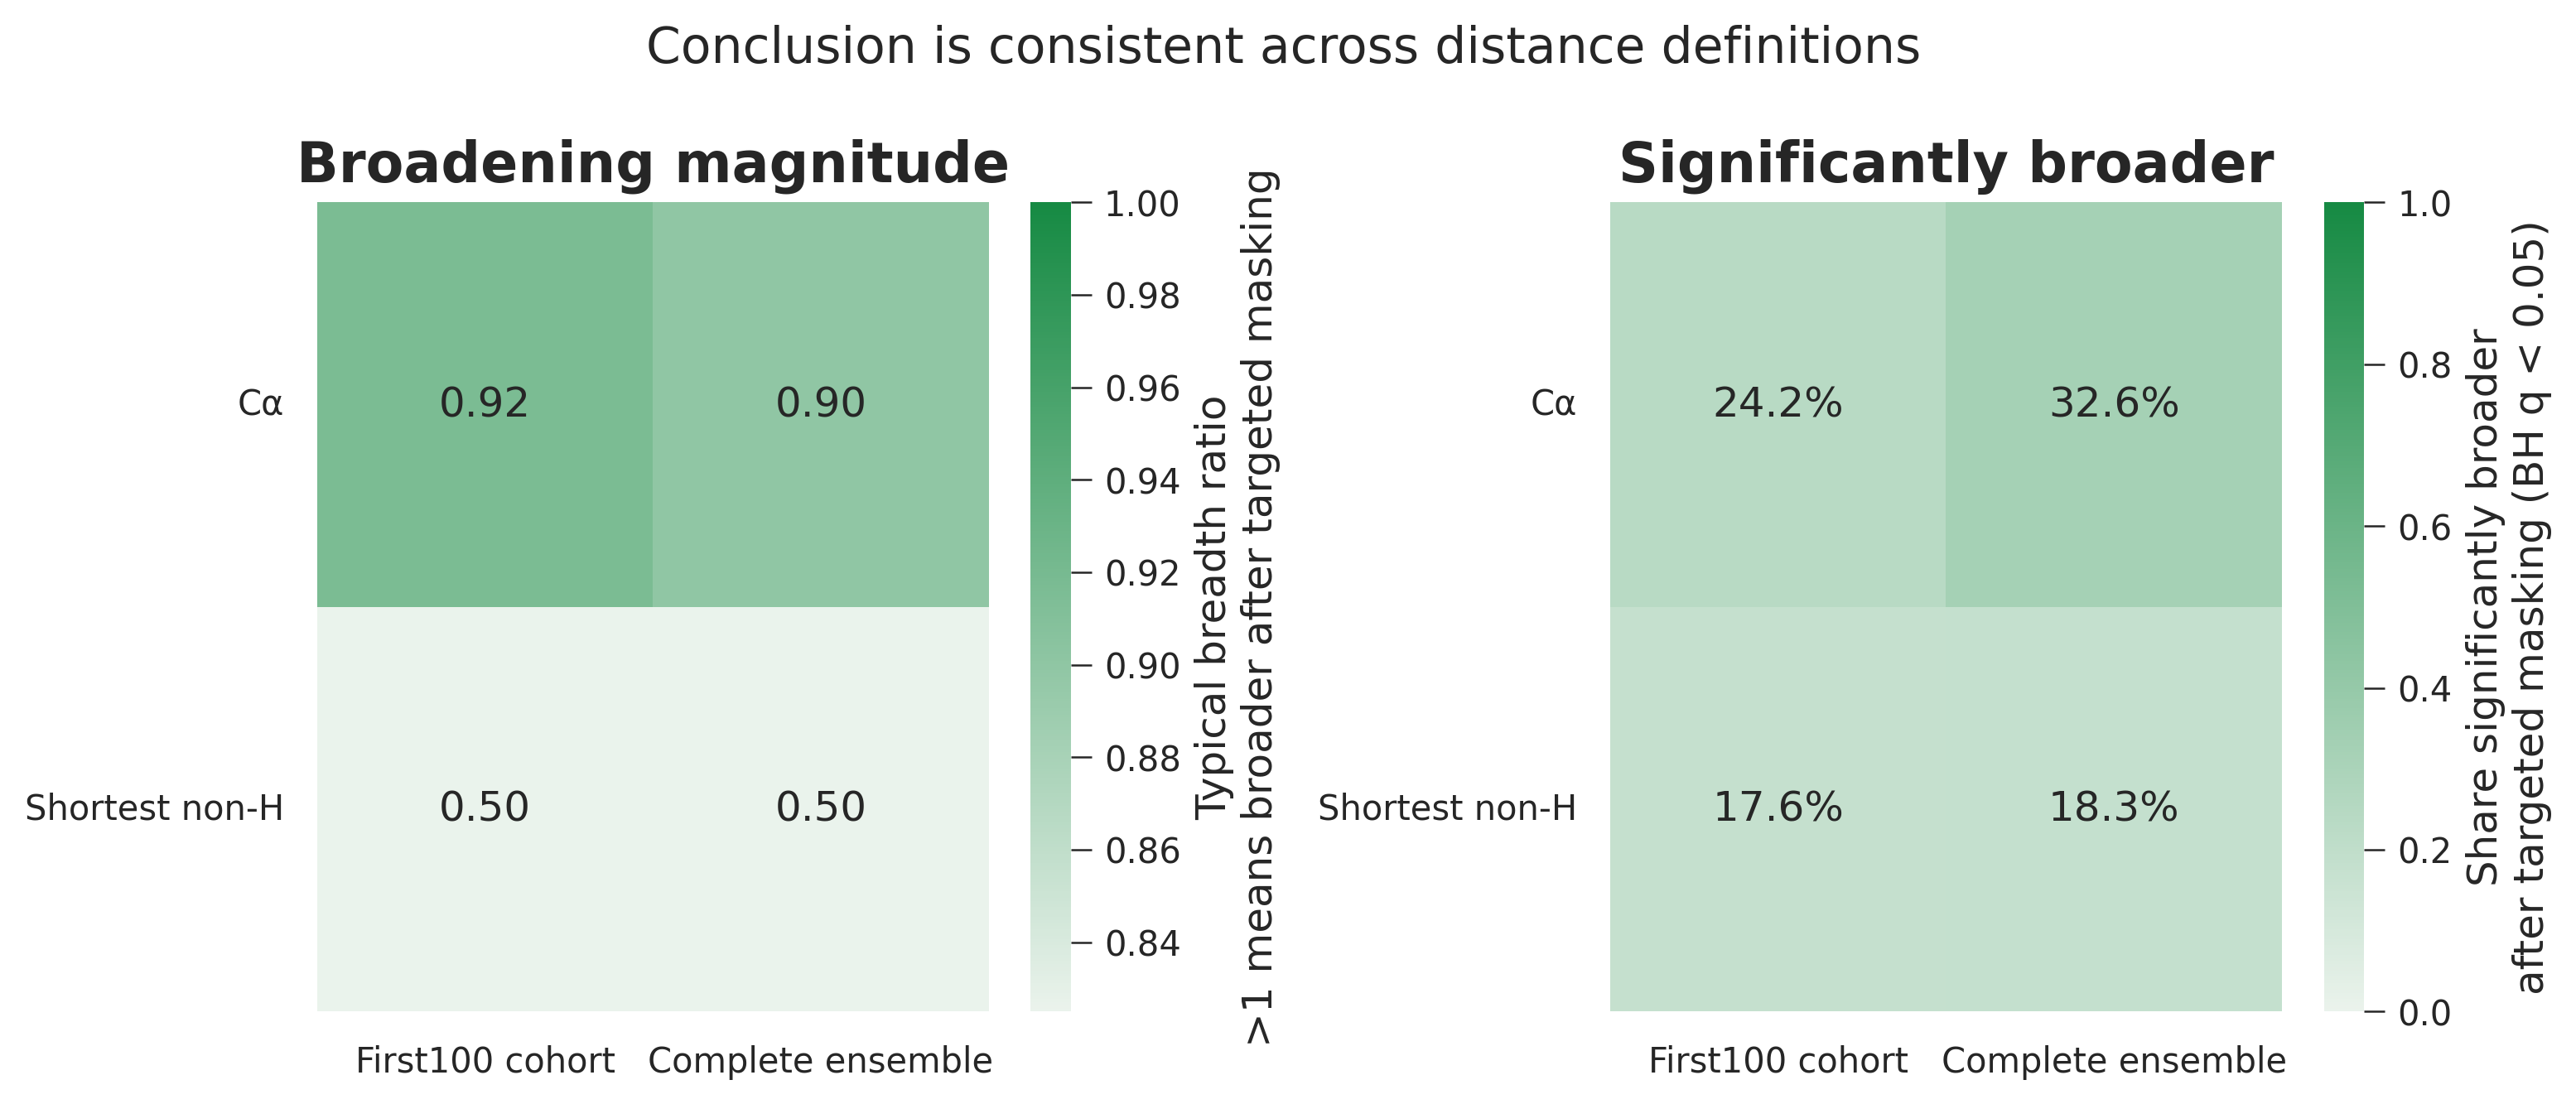

In [15]:
display(pd.read_csv(ALL_DISTANCE_TAB/'l403a_first100_vs_full_broadening_concordance.csv', index_col=0))
display(Image(filename=str(ALL_DISTANCE_FIG/'first100_vs_full_broadening_concordance_heatmap.png')))
display(Image(filename=str(ALL_DISTANCE_FIG/'first100_vs_full_breadth_quadrant_scatter.png')))
display(pd.read_csv(ALL_DISTANCE_TAB/'l403a_first100_vs_full_breadth_by_distance_type.csv'))
display(Image(filename=str(ALL_DISTANCE_FIG/'first100_vs_full_breadth_by_distance_type_heatmaps.png')))

### Random-seed sampling-efficiency and saturation curves

,seeds_sampled,iterations,vanilla_retention_fraction_median,vanilla_retention_fraction_CI_low,vanilla_retention_fraction_CI_high,masked_retention_fraction_median,masked_retention_fraction_CI_low,masked_retention_fraction_CI_high,vanilla_normalized_breadth_median,vanilla_normalized_breadth_CI_low,...,vanilla_fraction_full_breadth_median,vanilla_fraction_full_breadth_CI_low,vanilla_fraction_full_breadth_CI_high,masked_fraction_full_breadth_median,masked_fraction_full_breadth_CI_low,masked_fraction_full_breadth_CI_high,breadth_gain_masked_over_vanilla_median,breadth_gain_masked_over_vanilla_CI_low,breadth_gain_masked_over_vanilla_CI_high,fraction_draws_gain_gt_1
0,5,1000,0.960,0.880,1.000000,1.000000,0.960,1.000000,0.727380,0.629328,...,0.907002,0.784736,1.014416,0.907407,0.777778,0.986493,0.797049,0.675056,0.946306,0.004
1,10,1000,0.980,0.920,1.000000,1.000000,0.960,1.000000,0.769231,0.691382,...,0.959188,0.862114,1.029440,0.940876,0.860559,1.037037,0.795441,0.708459,0.897273,0.001
2,20,1000,0.970,0.930,1.000000,1.000000,0.980,1.000000,0.782292,0.750000,...,0.975474,0.935208,1.029535,0.972222,0.915848,1.031171,0.794430,0.733512,0.862745,0.000
3,25,1000,0.968,0.936,0.992000,0.992000,0.984,1.000000,0.789409,0.750000,...,0.984348,0.935208,1.029671,0.972222,0.927170,1.037037,0.792632,0.738444,0.857143,0.000
4,50,1000,0.968,0.952,0.984000,0.996000,0.988,1.000000,0.800000,0.775229,...,0.997555,0.966667,1.025986,0.989899,0.946206,1.033267,0.797971,0.760060,0.836411,0.000
5,75,1000,0.968,0.960,0.978667,0.994667,0.992,0.997333,0.800000,0.777778,...,0.997555,0.969845,1.020227,1.000000,0.972222,1.029052,0.802490,0.776675,0.831968,0.000
6,100,1,0.968,0.968,0.968000,0.994000,0.994,0.994000,0.801961,0.801961,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.801607,0.801607,0.801607,0.000


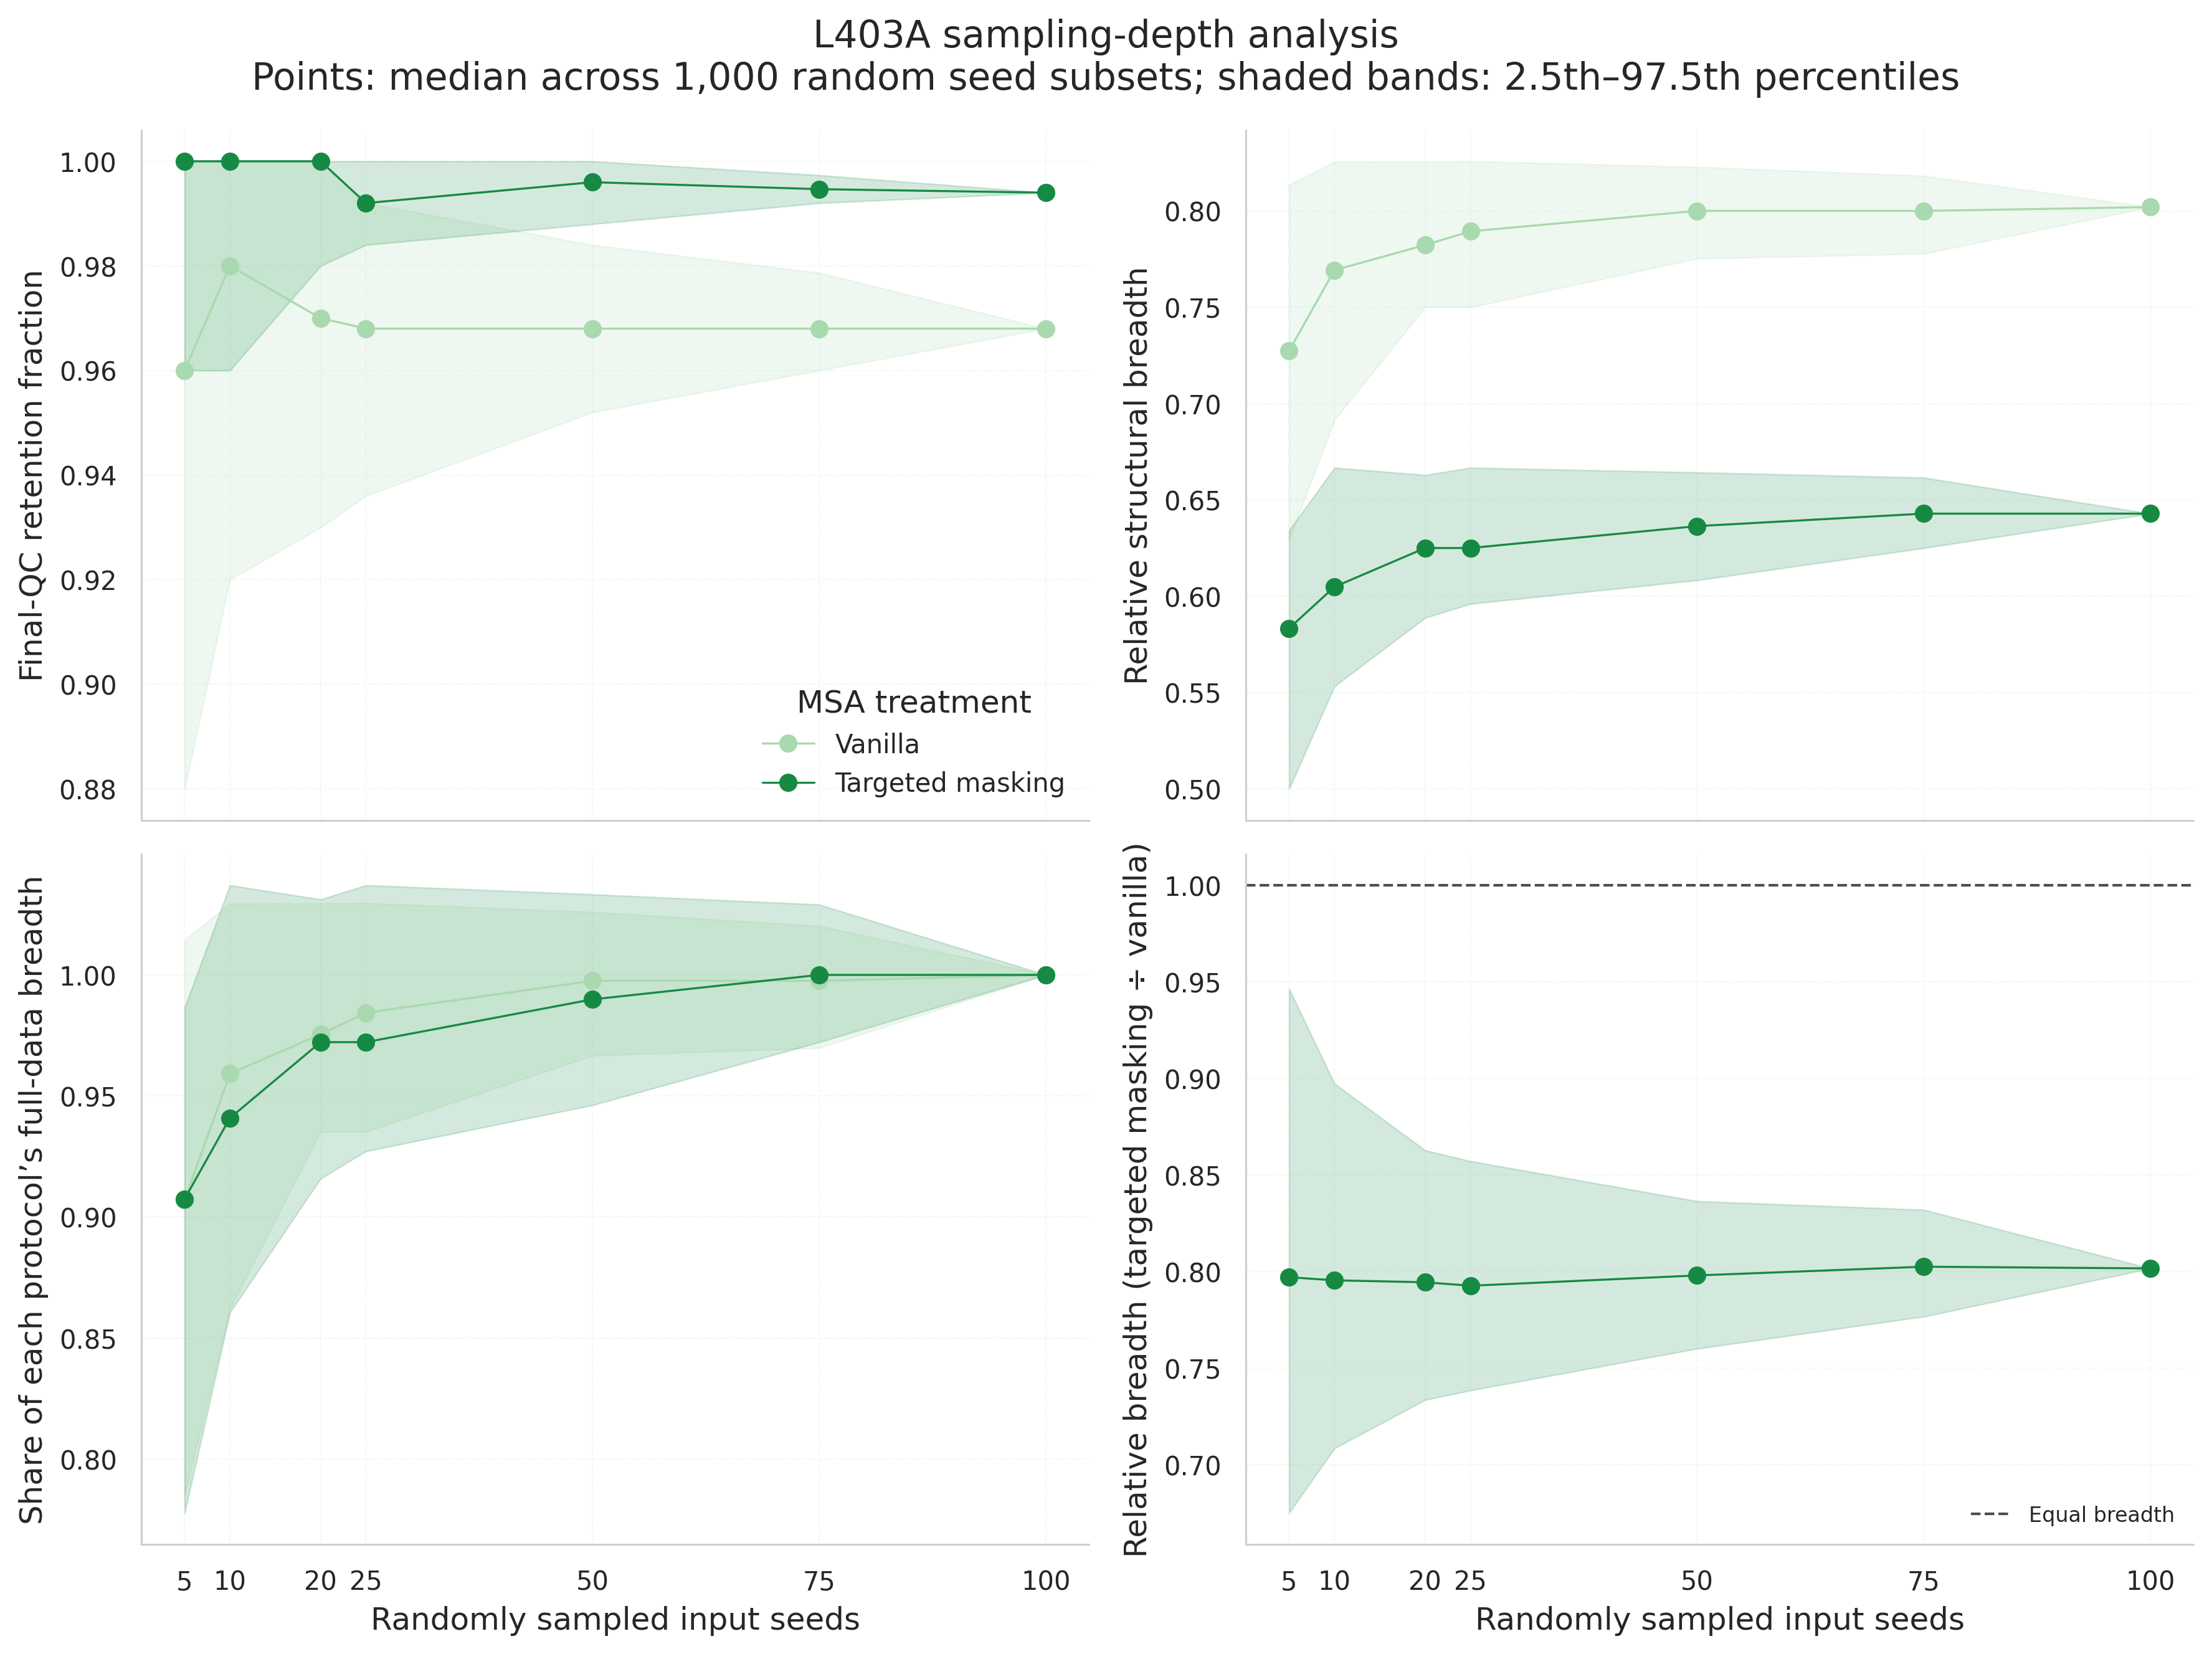

In [16]:
display(random_seed_saturation_summary)
display(Image(filename=str(ALL_DISTANCE_FIG/'random_seed_sampling_efficiency_saturation.png')))

### How widespread is masked broadening across sampling depth?

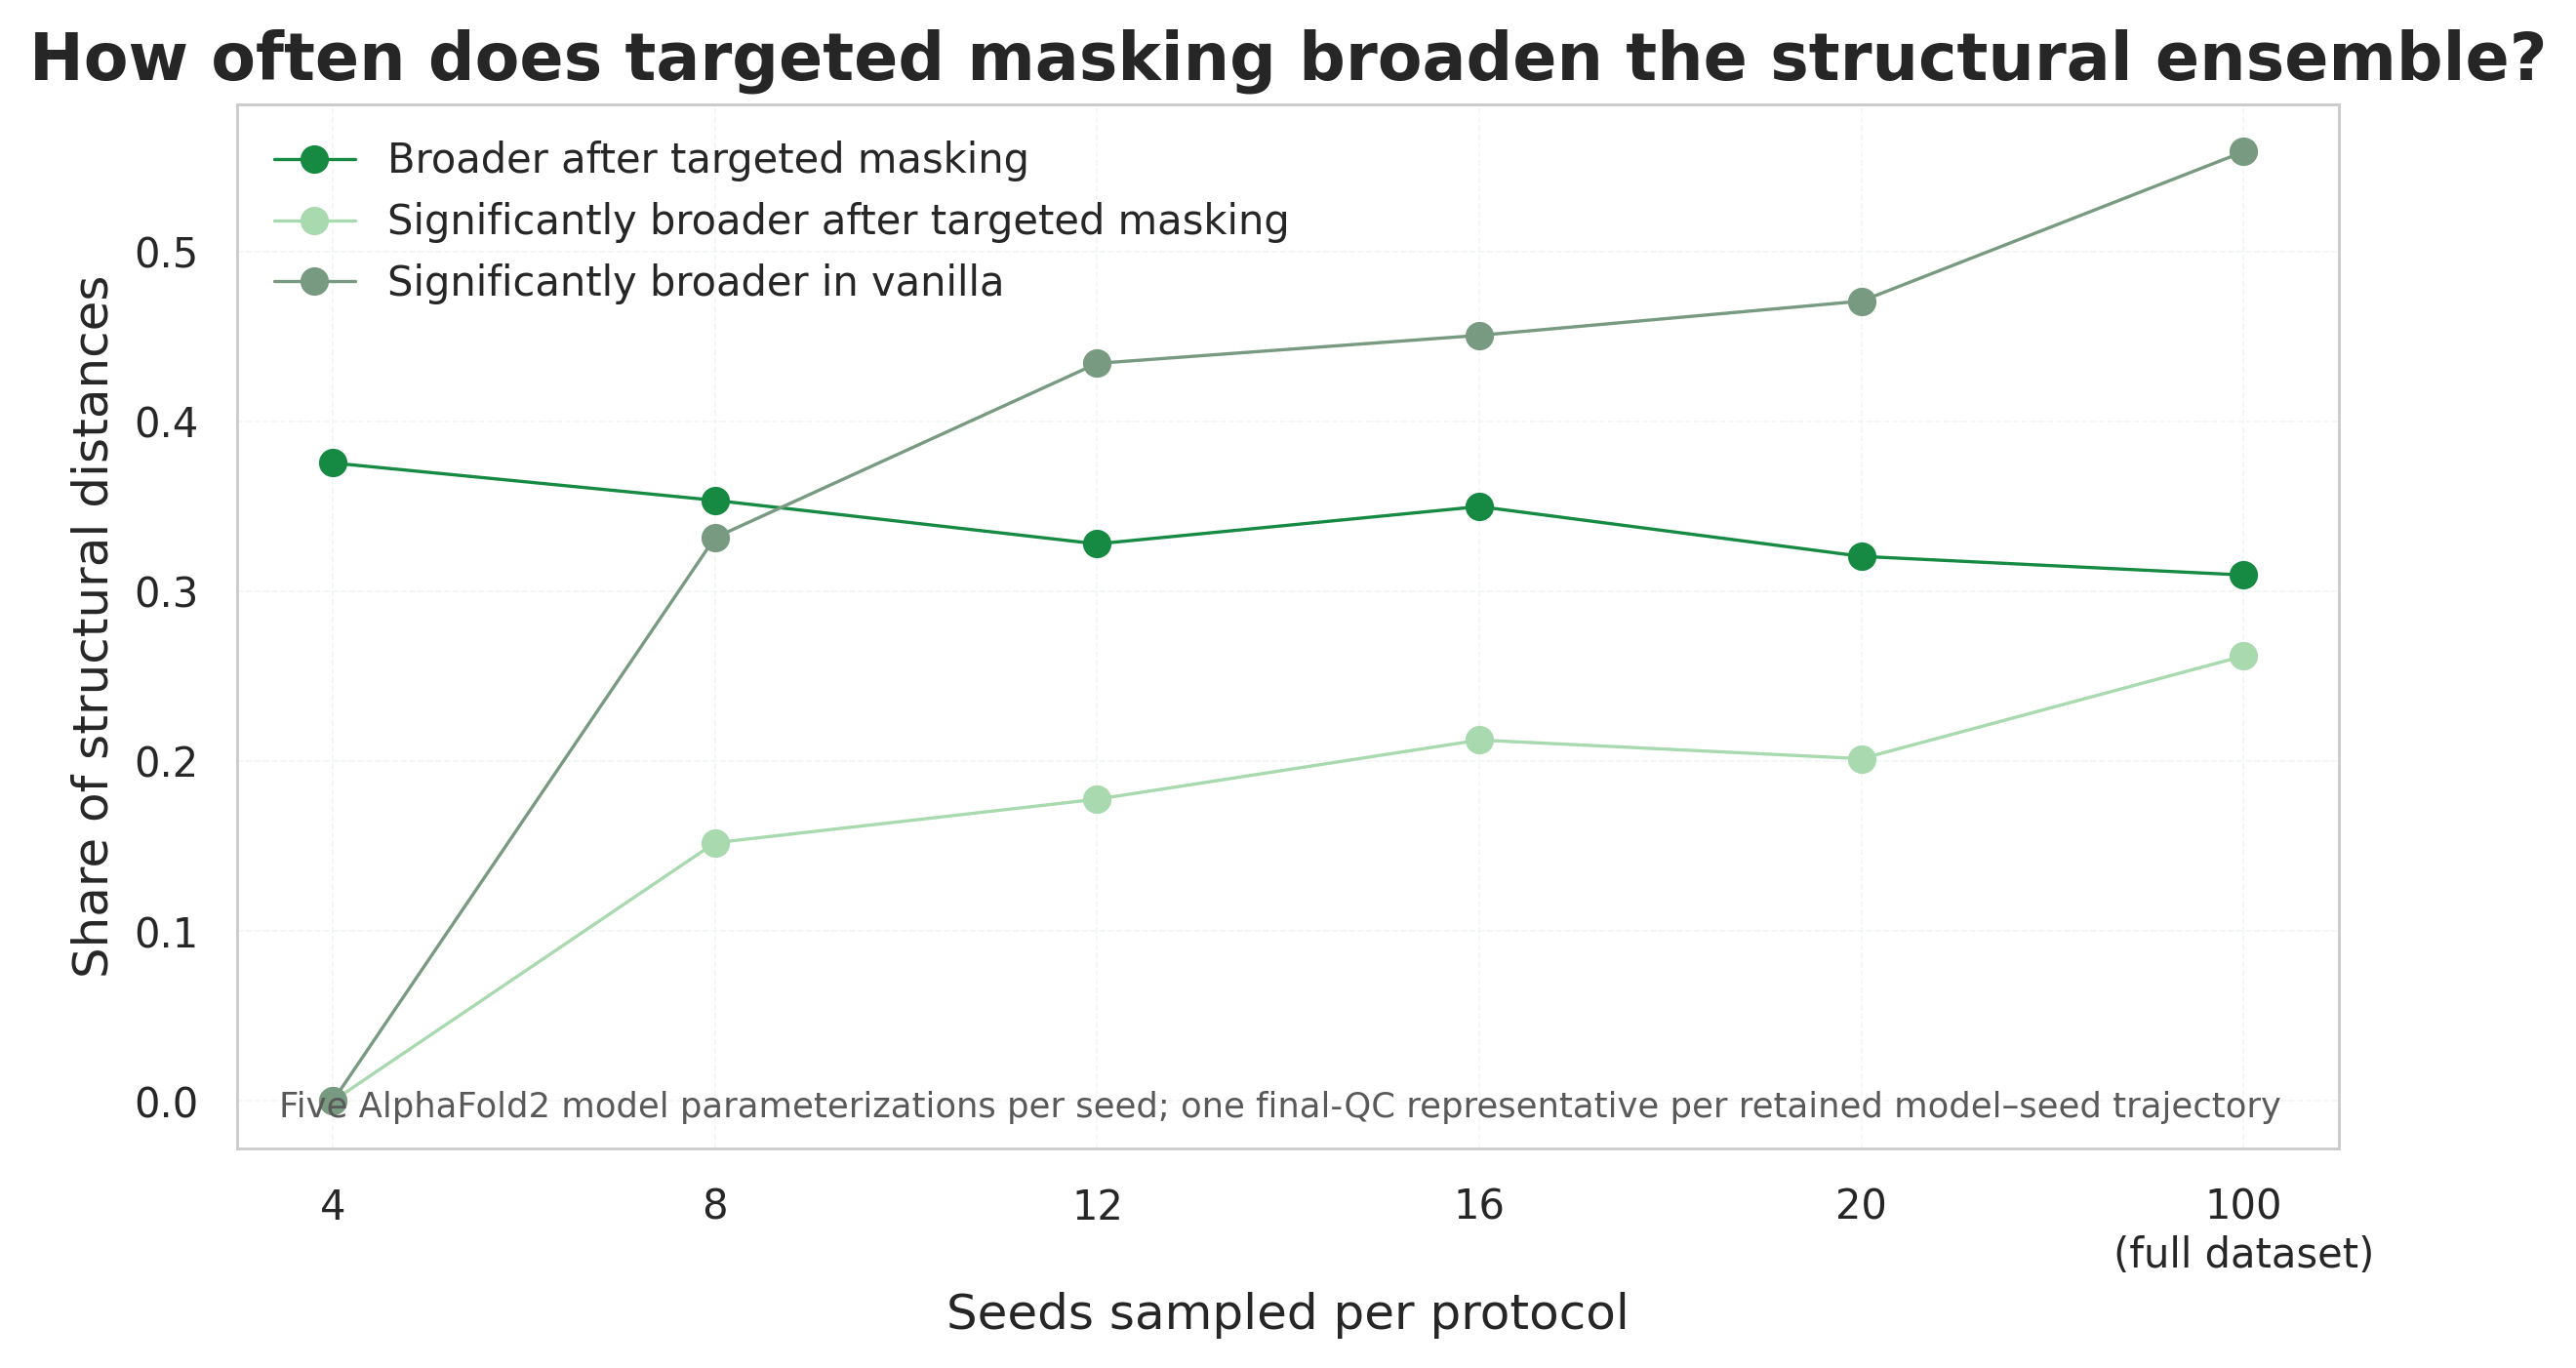

In [17]:
display(Image(filename=str(ALL_DISTANCE_FIG/'all_distance_breadth_fraction_by_depth.png')))

### QC survivors from the nominal first 100 versus full-QC breadth

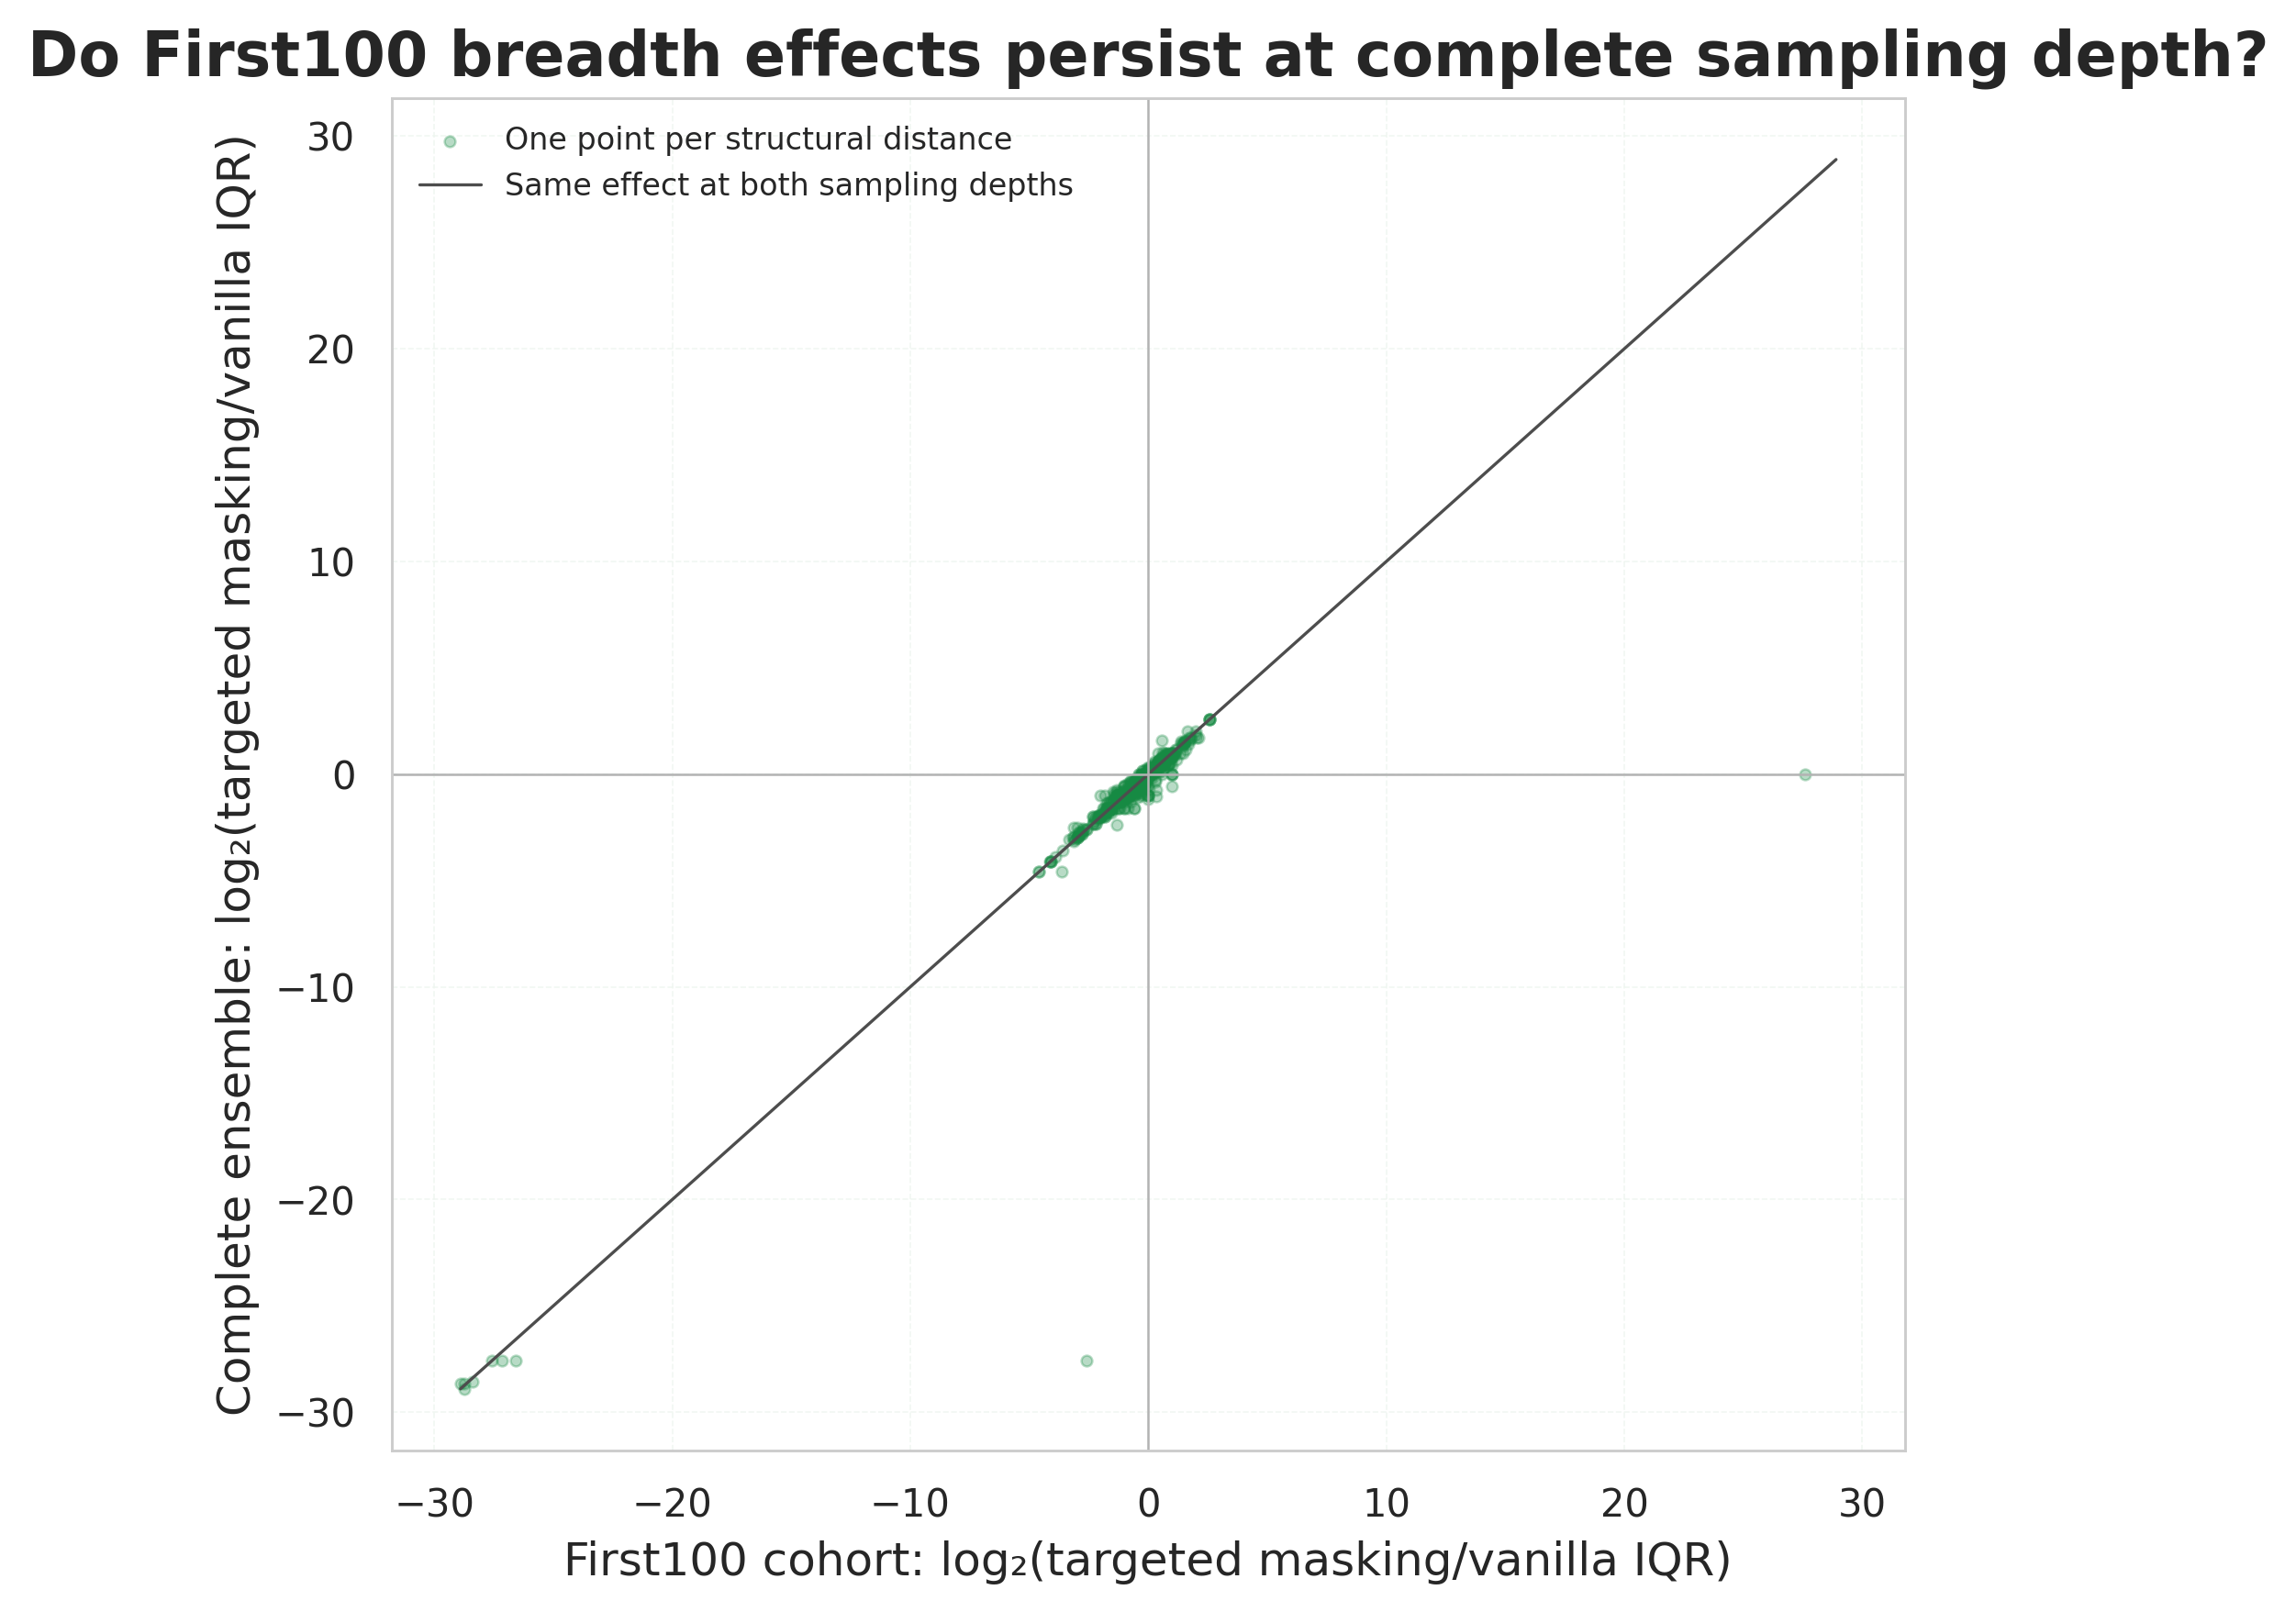

In [18]:
display(Image(filename=str(ALL_DISTANCE_FIG/'first100_nominal_vs_full_distance_breadth.png')))

### Ensemble-wide distribution of masked/vanilla IQR ratios

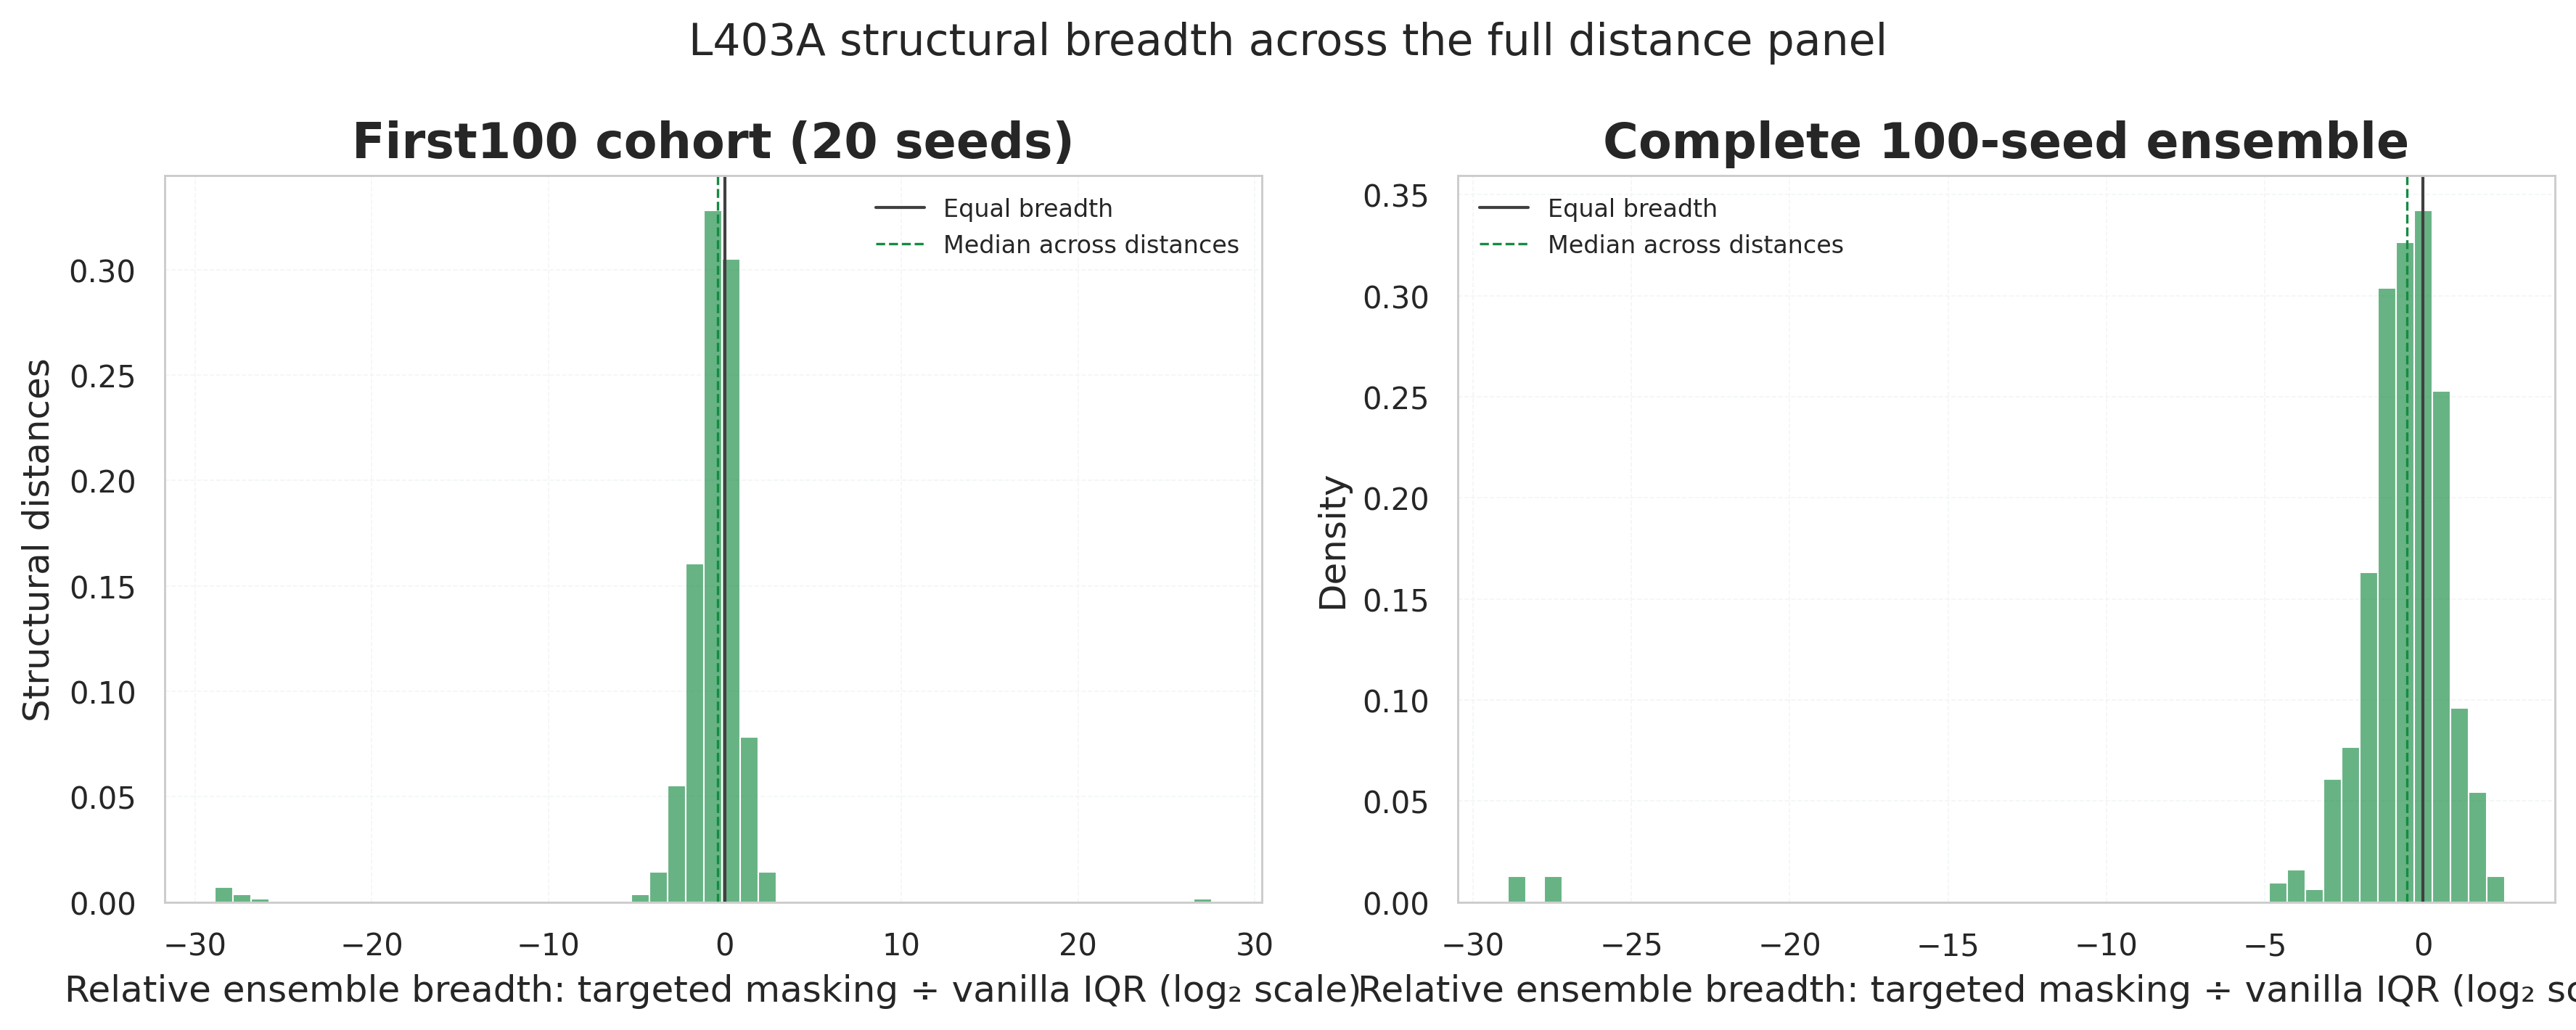

In [19]:
display(Image(filename=str(ALL_DISTANCE_FIG/'all_distance_iqr_ratio_distributions.png')))

### Strongest reproducible broadened and narrowed contacts

,distance,depth,vanilla_global_IQR_A,masked_global_IQR_A,global_IQR_ratio,vanilla_median_seed_IQR_A,masked_median_seed_IQR_A,seed_IQR_ratio,seed_breadth_q,trajectory_median_W1_A,W1_normalized_pooled_IQR
0,shortest_ARG304A-PHE238A,20,0.200,1.2000,6.000000e+00,0.20000,1.100,5.500000e+00,5.507150e-07,3.318232,1.124825
1,shortest_ARG304B-PHE238B,20,0.200,1.2000,6.000000e+00,0.20000,1.100,5.500000e+00,5.507150e-07,3.371273,1.087507
2,shortest_ARG304C-PHE238C,20,0.200,1.2000,6.000000e+00,0.20000,1.100,5.500000e+00,1.042853e-06,3.345141,1.115047
3,shortest_ARG304D-PHE238D,20,0.200,1.2000,6.000000e+00,0.20000,1.050,5.250000e+00,5.507150e-07,3.347162,1.115721
4,shortest_ARG301D-ASP223D,20,0.100,0.4000,4.000000e+00,0.10000,0.300,3.000000e+00,2.337209e-06,0.687293,1.145488
5,CA_CA_A_ARG304_CA-A_CYS234_CA,20,0.045,0.1800,4.000000e+00,0.03000,0.160,5.333333e+00,5.507150e-07,0.078312,0.978902
6,shortest_ARG304A-CYS234A,20,0.400,1.3250,3.312500e+00,0.30000,1.200,4.000000e+00,5.507150e-07,2.023354,1.190208
7,shortest_ARG304B-CYS234B,20,0.300,1.2250,4.083333e+00,0.20000,1.200,6.000000e+00,5.507150e-07,2.091404,1.130489
8,shortest_ARG304C-CYS234C,20,0.300,1.3000,4.333333e+00,0.20000,1.200,6.000000e+00,5.507150e-07,2.077535,1.154186
9,shortest_ARG304D-CYS234D,20,0.350,1.2000,3.428571e+00,0.30000,1.200,4.000000e+00,5.507150e-07,2.052515,1.207362


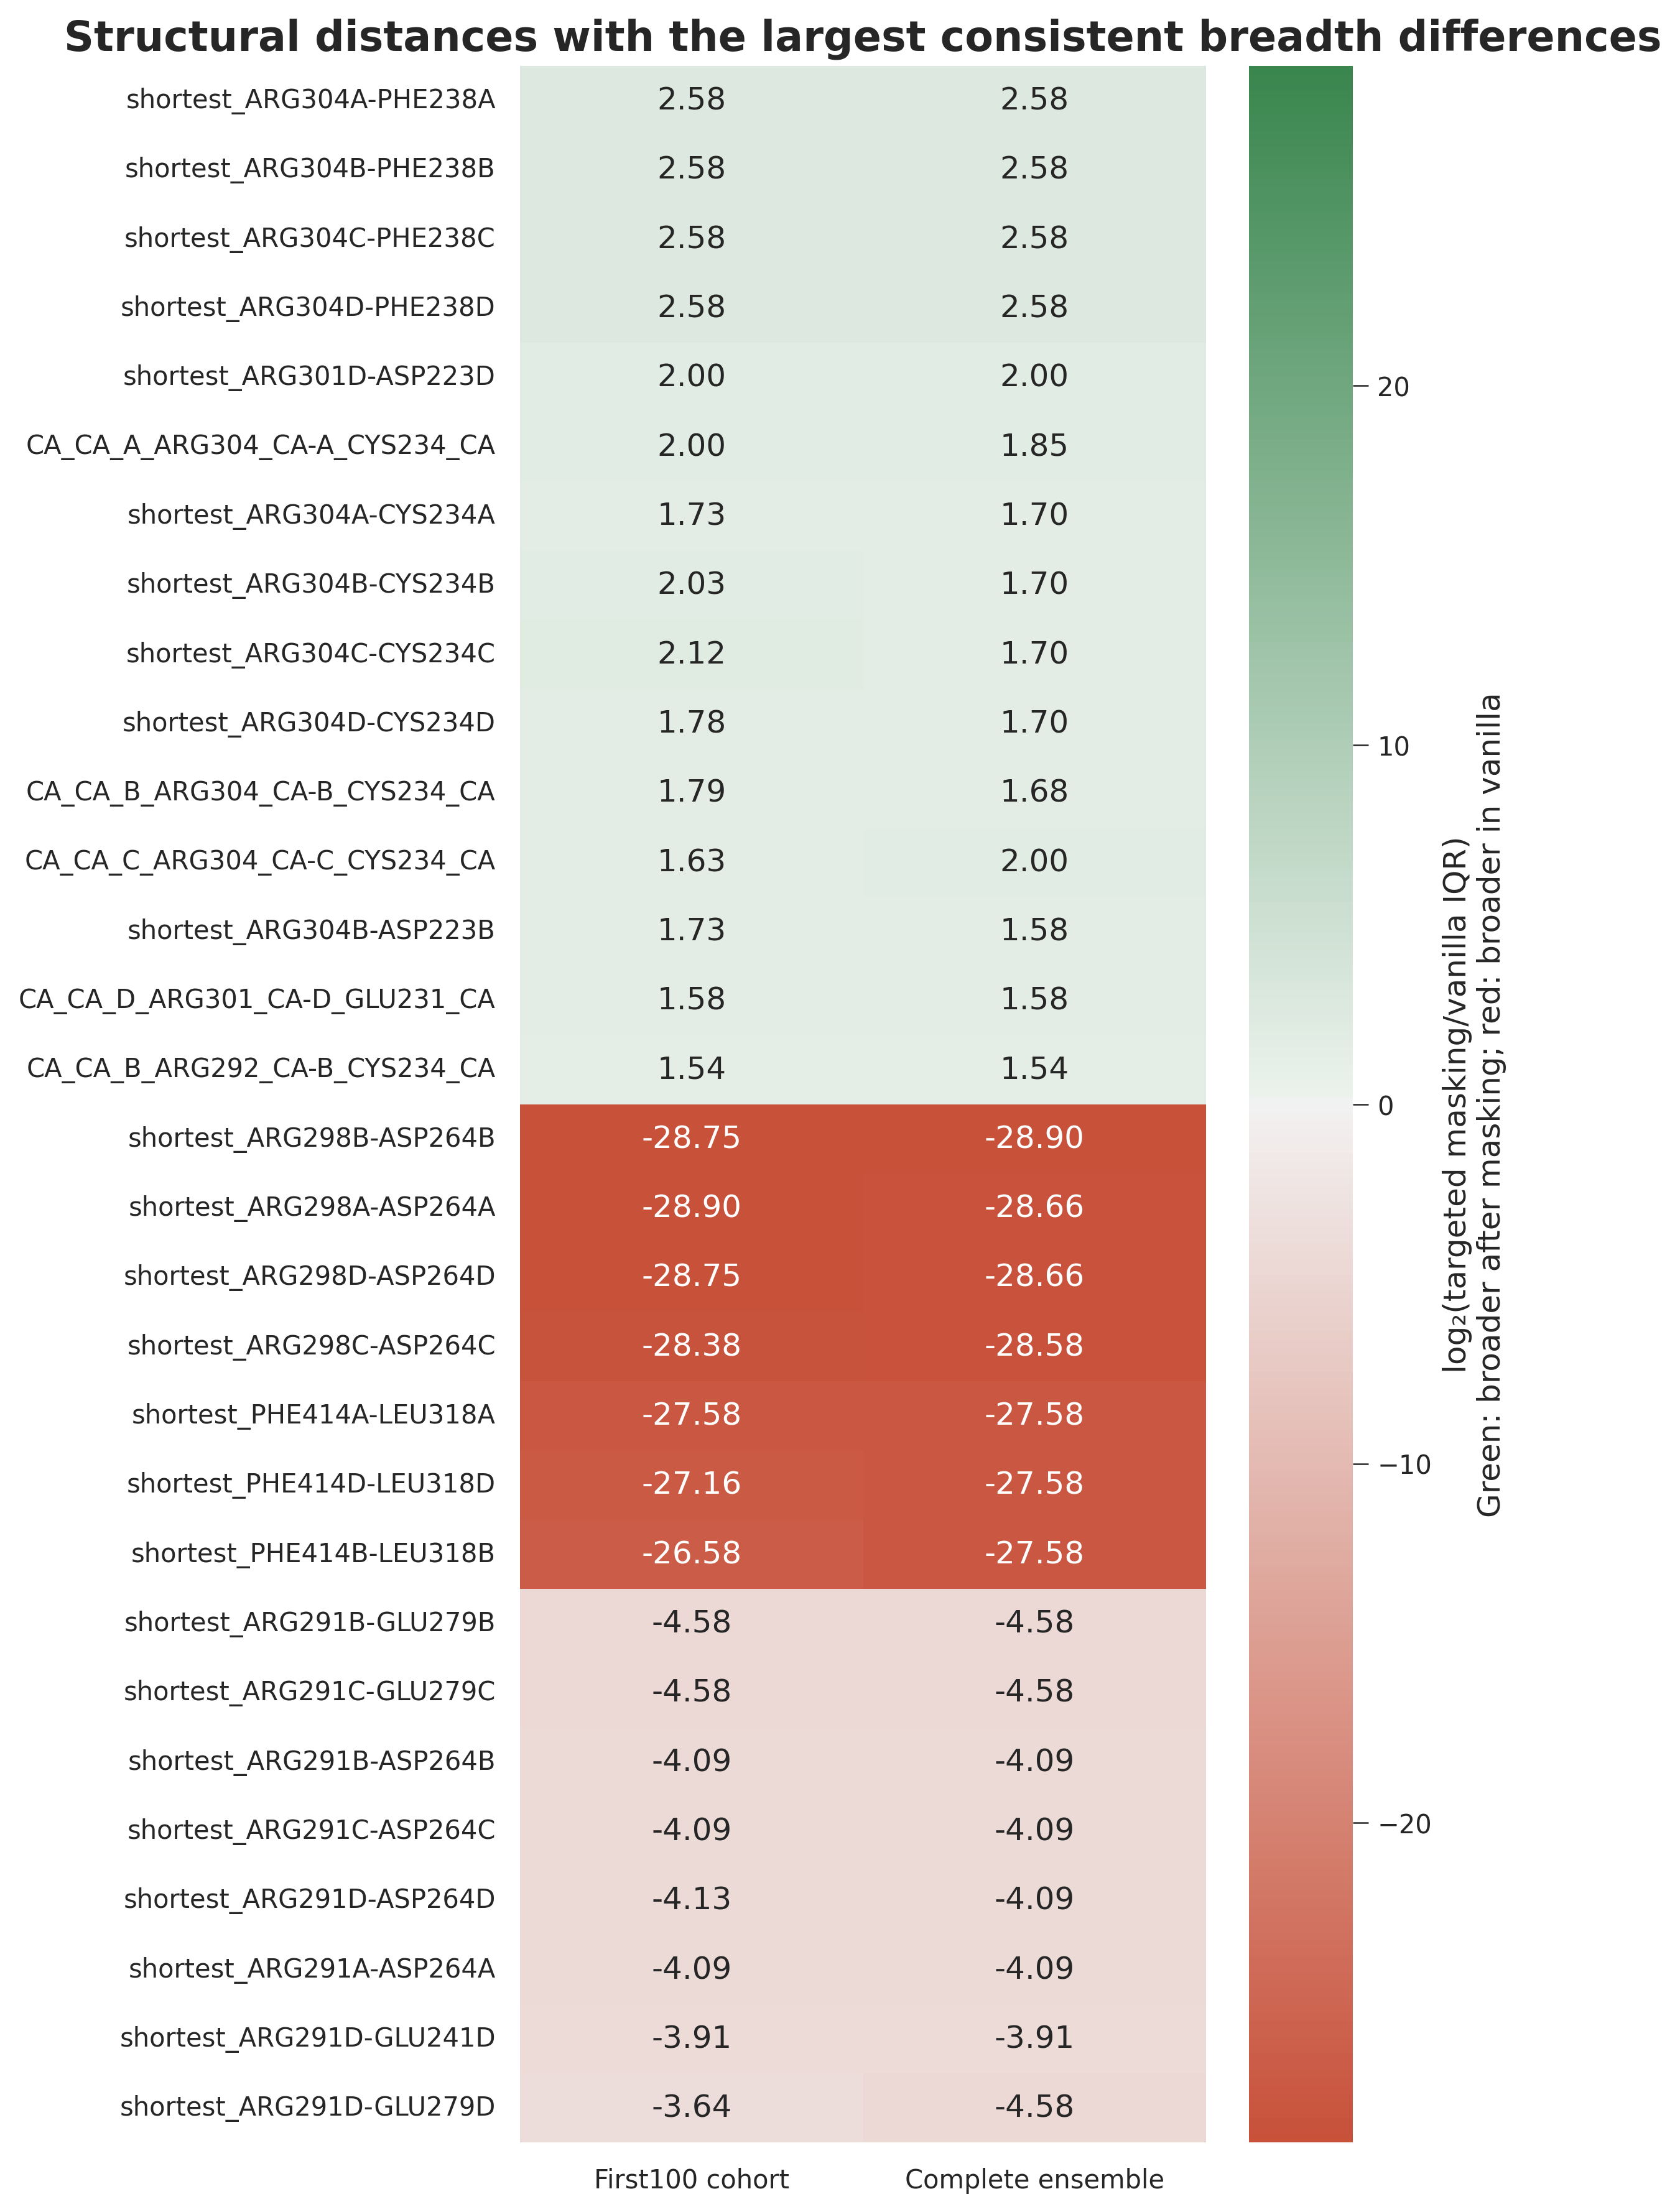

In [20]:
display(pd.read_csv(ALL_DISTANCE_TAB/'top_concordant_distance_statistical_details.csv'))
display(Image(filename=str(ALL_DISTANCE_FIG/'top_all_distance_breadth_heatmap.png')))

### Representative chain-label-safe intrachain distance distributions

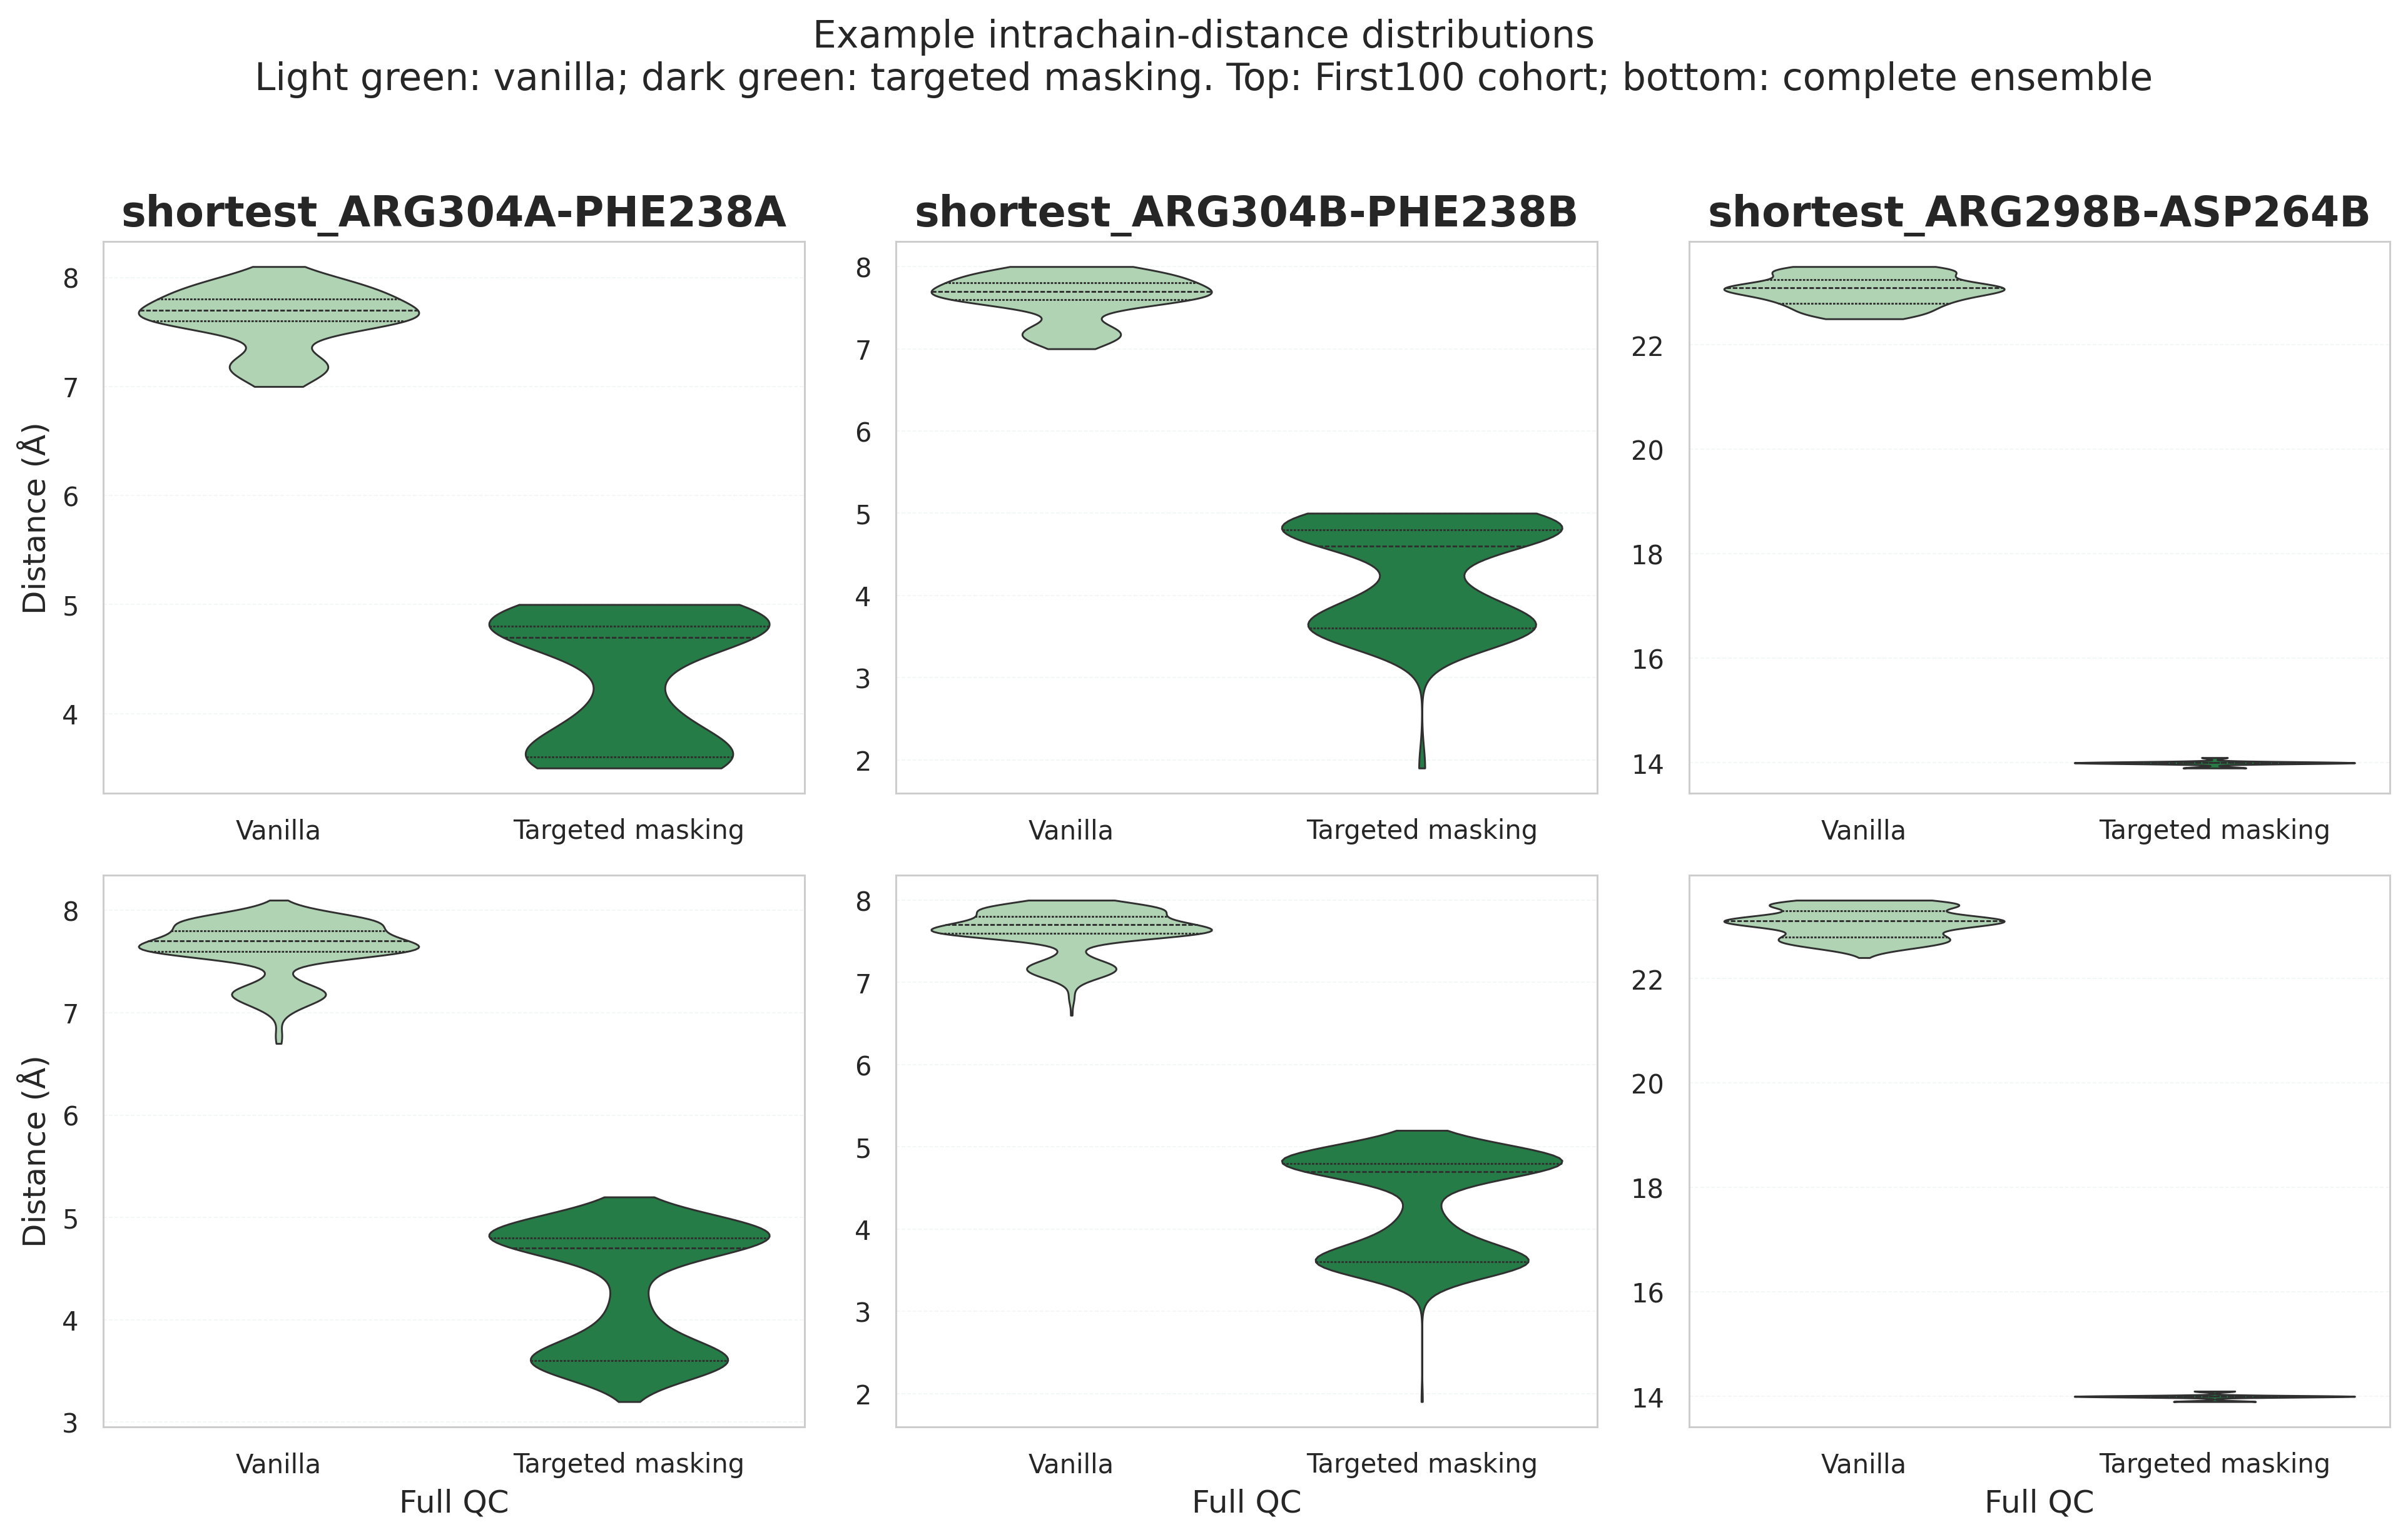

In [21]:
display(Image(filename=str(ALL_DISTANCE_FIG/'representative_all_distance_distributions.png')))

### Statistical quantities used in this extension

- **Effect size:** masked/vanilla global IQR ratio and log2 ratio for each distance.
- **Chain safety:** raw Kv2.1 interchain columns are excluded; inference uses 546 same-chain distances that are invariant to subunit relabeling.
- **Trajectory representation:** latest final-QC recycle, one structure per surviving seed/model trajectory.
- **Cluster-aware breadth:** median within-seed IQR and masked/vanilla seed-IQR ratio.
- **Primary per-distance inference:** two-sided Mann–Whitney comparison of seed IQRs with within-depth BH-FDR (`seed_breadth_q`).
- **Overall breadth test:** one median normalized all-distance IQR per seed, compared as 20 vanilla versus 20 masked seeds.
- **Standard distribution test:** W1 and normalized W1 per distance, with 999 unpaired seed-block permutations, 500 seed-block bootstrap replicates, and BH-FDR across the 546 intrachain distances.
- **Sensitivity analyses:** trajectory-level Brown–Forsythe tests and repeated vanilla rarefaction to 85 retained trajectories.
- **Sampling saturation:** 1,000 random seed subsets at 5, 10, 20, 25, 50, 75, and 100 input seeds.
- **Distributional separation:** Wasserstein distance between one representative per retained trajectory, in Å and normalized by pooled IQR.
- **Sampling-depth reproducibility:** Spearman correlation and sign agreement between QC survivors from the nominal first-100 cohort (20 seeds × five models) and full-QC distance effects.

Very large ratios can result when the vanilla IQR is nearly zero. Individual highlighted contacts should therefore be reported with both raw IQRs and Wasserstein effect sizes, not ratios alone.